## Outlier removal

In [ ]:
#  DATA LOADING & VALIDATION

# Download data (your original commands)
!gdown --quiet 1fcPnb6nzGb5rSxb8pqV77uovL6tSiLrK
!unzip -q an2dl2526c2v2.zip

import os
import numpy as np
from PIL import Image
import pandas as pd

# --- CONFIGURATION ---
TRAIN_DATA_DIR = 'train_data'

# Load labels dataframe
labels_df = pd.read_csv('train_labels.csv')

# Load list of training images from directory
train_images = sorted([f for f in os.listdir(TRAIN_DATA_DIR) if f.startswith('img_')])

# UPDATED THRESHOLDS (The "Yellow" Fix) for outlier detection
# OpenCV Hue scale is 0-179.
# Yellow starts ~20. Green is ~60. Cyan is ~90.
# Pink/Red (Valid Tissue) is usually 0-10 or 160-180.
HUE_MIN = 10   # Lowered from 40 to 20 to catch Yellow/Chartreuse artifacts
HUE_MAX = 100  # Stays at 100 to catch Cyan/Green artifacts
SAT_MIN = 25   # Slightly lowered to catch faded artifact images
VAL_MIN = 20   # Avoid analyzing pure black pixels
# ---------------------

def detect_outliers(data_dir, pixel_threshold=0.051):
    """
    Detect potential junk/artifact images based on HSV color analysis.

    Args:
        data_dir: Directory containing training images
        pixel_threshold: Ratio of artifact pixels to flag an image (default: ~5%)

    Returns:
        List of tuples (img_path, ratio, img_np, final_mask)
    """
    image_paths = sorted([os.path.join(data_dir, f) for f in train_images])
    flagged_images = []

    print(f"🔍 Scanning {len(image_paths)} images with Broad-Spectrum (Yellow-Green) Filter...")

    for img_path in image_paths:
        try:
            # Load and convert to HSV
            img = Image.open(img_path).convert('RGB')
            img_np = np.array(img)

            # Convert to HSV using OpenCV (H: 0-179, S: 0-255, V: 0-255)
            hsv = cv2.cvtColor(img_np, cv2.COLOR_RGB2HSV)
            h = hsv[:, :, 0]  # Hue
            s = hsv[:, :, 1]  # Saturation
            v = hsv[:, :, 2]  # Value

            # 1. Color Check: Is it Yellow, Green, or Cyan? (Hue 10-100)
            col_mask = (h >= HUE_MIN) & (h <= HUE_MAX)

            # 2. Saturation Check: Is it colorful? (Ignores Grey/White background)
            sat_mask = (s > SAT_MIN)

            # 3. Value Check: Is it not pitch black?
            val_mask = (v > VAL_MIN)

            # Combine all conditions
            final_mask = col_mask & sat_mask & val_mask

            # Calculate ratio of artifact pixels
            ratio = np.sum(final_mask) / final_mask.size

            if ratio > pixel_threshold:
                flagged_images.append((img_path, ratio, img_np, final_mask))

        except Exception as e:
            print(f"⚠️  Error processing {img_path}: {e}")

    # Sort by "Badness" (highest ratio first)
    flagged_images.sort(key=lambda x: x[1], reverse=True)

    print(f"\n🚨 Found {len(flagged_images)} potential outliers.")
    return flagged_images

detectionflagged_data = detect_outliers(TRAIN_DATA_DIR)
flagged_image_paths = [x[0] for x in detectionflagged_data]

🔍 Scanning 691 images with Broad-Spectrum (Yellow-Green) Filter...

🚨 Found 60 potential outliers.



📊 Label Distribution of Flagged Images:
  HER2(+): 30 (50.0%)
  Luminal A: 30 (50.0%)


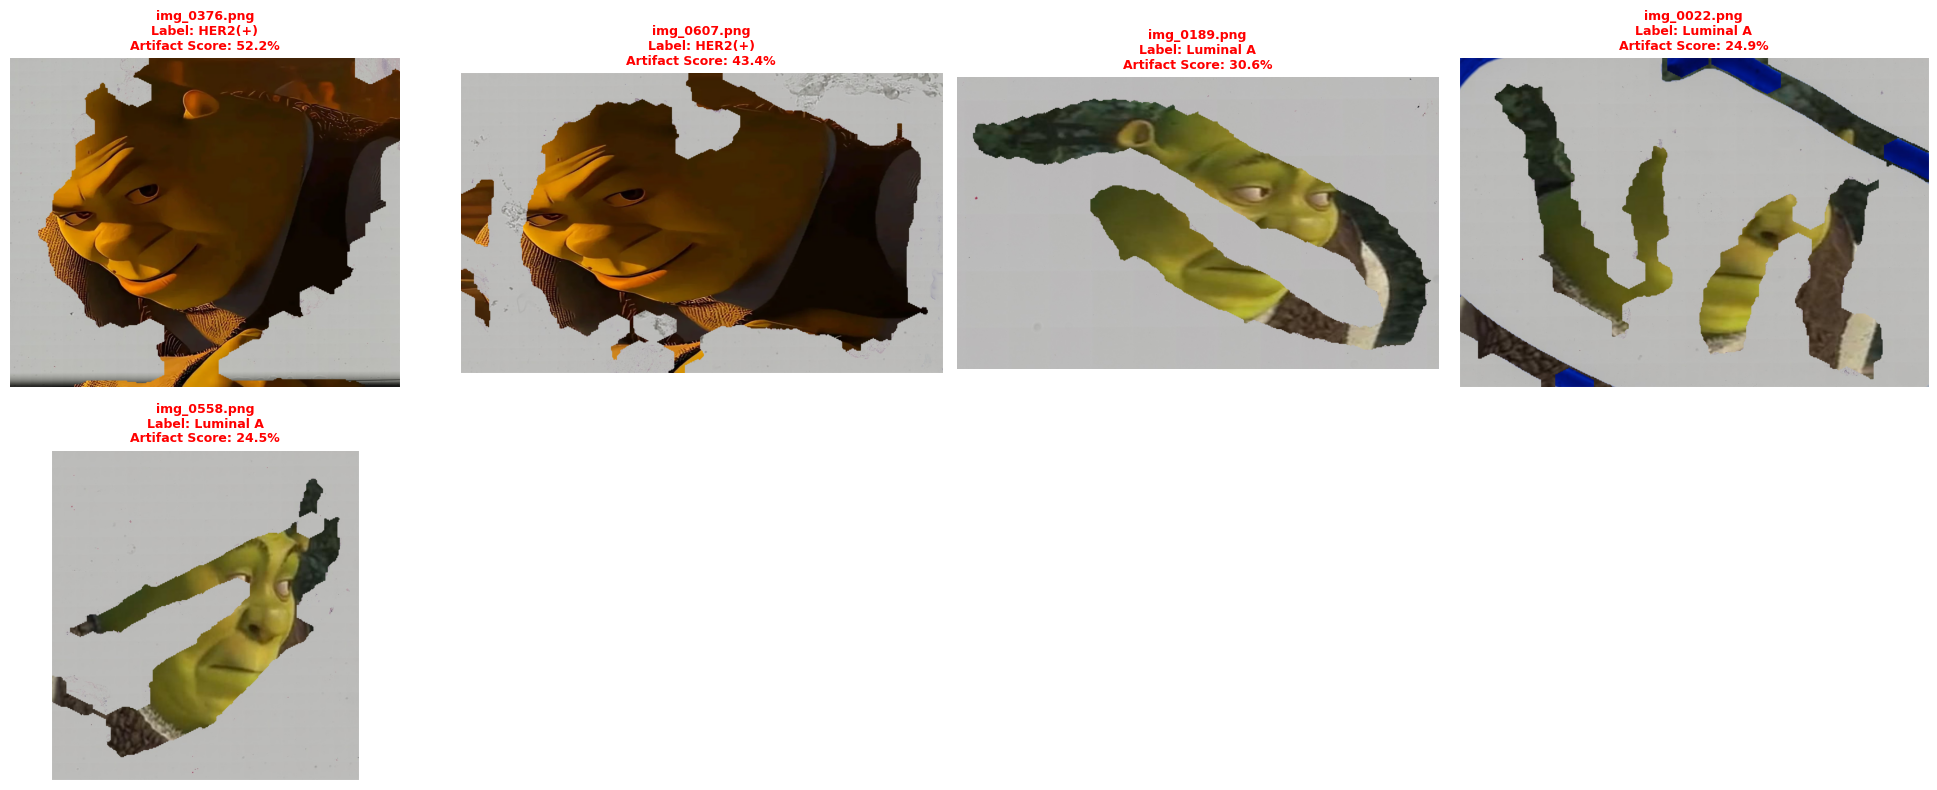

In [ ]:
# ========================================
# OUTLIER VISUALIZATION AND REMOVAL
# ========================================

import matplotlib.pyplot as plt

def visualize_outliers(flagged_images, show_count=20):
    """
    Visualize flagged images with labels.

    Args:
        flagged_images: List of tuples (img_path, ratio, img_np, final_mask)
        show_count: Maximum number of flagged images to display
    """
    if len(flagged_images) > 0:
        # Compute label distribution of flagged images
        flagged_labels = []
        for path, _, _, _ in flagged_images:
            fname = os.path.basename(path)
            label_row = labels_df[labels_df['sample_index'] == fname]
            if not label_row.empty:
                flagged_labels.append(label_row.iloc[0]['label'])

        # Display distribution
        if flagged_labels:
            from collections import Counter
            label_counts = Counter(flagged_labels)
            print(f"\n📊 Label Distribution of Flagged Images:")
            for label, count in label_counts.items():
                print(f"  {label}: {count} ({count/len(flagged_labels)*100:.1f}%)")

        # Display flagged images
        top_n = min(len(flagged_images), show_count)
        rows = (top_n + 3) // 4  # Round up for rows
        plt.figure(figsize=(20, 4 * rows))

        for i in range(top_n):
            path, ratio, img, mask = flagged_images[i]
            fname = os.path.basename(path)

            # Get label for this image
            label_row = labels_df[labels_df['sample_index'] == fname]
            label_text = label_row.iloc[0]['label'] if not label_row.empty else 'Unknown'

            plt.subplot(rows, 4, i+1)
            plt.imshow(img)
            plt.title(f"{fname}\nLabel: {label_text}\nArtifact Score: {ratio:.1%}",
                      color='red', fontweight='bold', fontsize=9)
            plt.axis('off')

        plt.tight_layout()
        plt.show()

    else:
        print("✅ No outliers found with current thresholds.")

visualize_outliers(detectionflagged_data, show_count=5)


In [ ]:
def remove_flagged_images(flagged_paths):
    """Remove flagged images, their masks, and update the labels dataframe."""
    global labels_df, train_images
    removed_count = 0
    removed_ids = []
    removed_labels = []

    for img_path in flagged_paths:
        try:
            # Extract filename from path
            img_name = os.path.basename(img_path)
            mask_name = img_name.replace('img_', 'mask_')
            mask_path = os.path.join(TRAIN_DATA_DIR, mask_name)

            # Get label before removal
            label_row = labels_df[labels_df['sample_index'] == img_name]
            if not label_row.empty:
                removed_labels.append(label_row.iloc[0]['label'])

            # Remove image
            if os.path.exists(img_path):
                os.remove(img_path)
                print(f"🗑️  Removed: {img_path}")
                removed_count += 1
                removed_ids.append(img_name)  # Store full filename

            # Remove mask
            if os.path.exists(mask_path):
                os.remove(mask_path)
                print(f"🗑️  Removed: {mask_path}")

        except Exception as e:
            print(f"⚠️  Error removing {img_path}: {e}")

    # Show distribution of removed labels
    if removed_labels:
        from collections import Counter
        removed_label_counts = Counter(removed_labels)
        print(f"\n📊 Label Distribution of Removed Images:")
        for label, count in removed_label_counts.items():
            print(f"  {label}: {count} ({count/len(removed_labels)*100:.1f}%)")

    # Update train_images and train_masks lists
    train_images = sorted([f for f in os.listdir(TRAIN_DATA_DIR) if f.startswith('img_')])
    train_masks = sorted([f for f in os.listdir(TRAIN_DATA_DIR) if f.startswith('mask_')])
    print(f"📊 Remaining images in filesystem: {len(train_images)}")

    # Filter out removed images from CSV
    labels_df = labels_df[~labels_df['sample_index'].isin(removed_ids)]

    # Save updated labels
    labels_df.to_csv('train_labels.csv', index=False)
    print(f"\n✅ Removed {removed_count} images and updated train_labels.csv")
    print(f"📊 Remaining samples in CSV: {len(labels_df)}")

    return removed_count

# Remove flagged images (you can comment this out if you want to manually inspect first)
remove_flagged_images(flagged_image_paths)


🗑️  Removed: train_data/img_0376.png
🗑️  Removed: train_data/mask_0376.png
🗑️  Removed: train_data/img_0607.png
🗑️  Removed: train_data/mask_0607.png
🗑️  Removed: train_data/img_0189.png
🗑️  Removed: train_data/mask_0189.png
🗑️  Removed: train_data/img_0022.png
🗑️  Removed: train_data/mask_0022.png
🗑️  Removed: train_data/img_0558.png
🗑️  Removed: train_data/mask_0558.png
🗑️  Removed: train_data/img_0319.png
🗑️  Removed: train_data/mask_0319.png
🗑️  Removed: train_data/img_0390.png
🗑️  Removed: train_data/mask_0390.png
🗑️  Removed: train_data/img_0572.png
🗑️  Removed: train_data/mask_0572.png
🗑️  Removed: train_data/img_0521.png
🗑️  Removed: train_data/mask_0521.png
🗑️  Removed: train_data/img_0459.png
🗑️  Removed: train_data/mask_0459.png
🗑️  Removed: train_data/img_0499.png
🗑️  Removed: train_data/mask_0499.png
🗑️  Removed: train_data/img_0048.png
🗑️  Removed: train_data/mask_0048.png
🗑️  Removed: train_data/img_0540.png
🗑️  Removed: train_data/mask_0540.png
🗑️  Removed: train_data/i

60

# check tiles variances

In [ ]:
import cv2

def is_suspicious_blank_rgb(img_rgb, var_thresh=20):
    """
    Check if an RGB image is suspiciously blank/uniform.

    Args:
        img_rgb: RGB image as uint8 numpy array [H,W,3]
        var_thresh: Variance threshold below which image is considered blank

    Returns:
        True if variance < threshold (image is blank/suspicious)
    """
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    variance = gray.var()
    print(f'Image variance: {variance}')
    return variance < var_thresh

In [ ]:
import cv2
tiles_dir = Path('tiles/')

suspicious_tiles = []
for tile_path in sorted(tiles_dir.glob('img_*_tile_*.png')):
    # print(f'Checking {tile_path} for suspicious blankness...')
    img = np.array(Image.open(tile_path))
    if is_suspicious_blank_rgb(img, var_thresh=1):
        suspicious_tiles.append((tile_path.name, img))

print(f'Found {len(suspicious_tiles)} suspicious blank tiles')

if suspicious_tiles:
    n = len(suspicious_tiles)
    cols = min(4, n)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
    if n == 1:
        axes = np.array([axes])
    axes = axes.flatten()

    for i, (name, img) in enumerate(suspicious_tiles):
        axes[i].imshow(img)
        axes[i].set_title(name, fontsize=8)
        axes[i].axis('off')

    for i in range(n, len(axes)):
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print('No suspicious blank tiles found')

Image variance: 1120.4704569452297
Image variance: 1011.5993185257539
Image variance: 990.2458911579452
Image variance: 1152.9095531366765
Image variance: 3210.6211962195666
Image variance: 2766.947484569726
Image variance: 2963.1114067133603
Image variance: 2415.5416358917573
Image variance: 2015.7903336954769
Image variance: 1602.93705368042
Image variance: 1647.8447944687214
Image variance: 2936.9619595151744
Image variance: 2669.620737554913
Image variance: 775.4868602097122
Image variance: 2314.6292061091954
Image variance: 2202.282784094088
Image variance: 2254.8787491218536
Image variance: 1563.849764739265
Image variance: 2505.329836154575
Image variance: 2219.27759479206
Image variance: 2423.7032268170587
Image variance: 3359.688373591751
Image variance: 2668.5167054167105
Image variance: 1755.6559218047041
Image variance: 2524.2822821502923
Image variance: 2482.971963533608
Image variance: 2632.08084915216
Image variance: 2885.42429409083
Image variance: 2816.9775418207137
Im

In [ ]:
# find minimum variance among all tiles
min_variance = float('inf')
name = None
for tile_path in sorted(tiles_dir.glob('img_*_tile_*.png')):
    img = np.array(Image.open(tile_path))
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    variance = gray.var()
    if variance < min_variance:
        min_variance = variance
        name = tile_path
print(f'Minimum variance among all tiles: {min_variance}')
print(f'Tile with minimum variance: {name}')

Minimum variance among all tiles: 220.3887303754309
Tile with minimum variance: tiles\img_0173_tile_03.png


In [ ]:
# find top 20 images with lowest variance in tissue_extracted/img_*.png
min_variances = []
for img_path in sorted(root.glob('img_*.png')):
    img = np.array(Image.open(img_path))
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    variance = gray.var()
    min_variances.append((variance, img_path.name))
min_variances.sort()



In [ ]:
for variance, name in min_variances[:50]:
    print(f'{name}: {variance}')

img_0049.png: 19.7866091752594
img_0131.png: 22.312829266118158
img_0239.png: 28.230740332576225
img_0035.png: 29.05636538720479
img_0173.png: 31.345865654121543
img_0019.png: 35.562646943247906
img_0102.png: 38.12087027031899
img_0327.png: 41.22924667184848
img_0201.png: 46.81763789712477
img_0054.png: 48.64690104366219
img_0056.png: 49.073303977607345
img_0220.png: 49.956968767910915
img_0548.png: 51.45651619167481
img_0577.png: 53.9419805162176
img_0599.png: 54.65476615613043
img_0375.png: 58.11737660122449
img_0594.png: 58.92828718902206
img_0619.png: 59.501366300295985
img_0377.png: 60.63290159952703
img_0272.png: 60.73720425950266
img_0107.png: 63.738537690305314
img_0474.png: 64.14422293589175
img_0625.png: 64.26718018428798
img_0216.png: 64.71516536294924
img_0388.png: 67.32484442912079
img_0677.png: 68.16531304834376
img_0579.png: 68.19426366576694
img_0075.png: 70.05529275636982
img_0591.png: 70.25993842633878
img_0370.png: 70.42998670045819
img_0642.png: 71.17788870039125
im

In [ ]:
# visualize top 20 images with lowest variance
fig, axes = plt.subplots(10, 5, figsize=(15, 15))
for i, (variance, name) in enumerate(min_variances[:50]):
    img_path = root / name
    img = np.array(Image.open(img_path))
    ax = axes[i // 5, i % 5]
    ax.imshow(img)
    ax.set_title(f'{name}\nVariance: {variance:.2f}', fontsize=10)
    ax.axis('off')

In [ ]:
# find minimum variance among all tiles
max_variance = float('-inf')
name = None
for tile_path in sorted(root.glob('img_*_tile_*.png')):
    img = np.array(Image.open(tile_path))
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    variance = gray.var()
    if variance > max_variance:
        max_variance = variance
        name = tile_path
print(f'Maximum variance among all tiles: {max_variance}')
print(f'Tile with maximum variance: {name}')

Maximum variance among all tiles: 7108.489197127288
Tile with maximum variance: tiles\img_0517_tile_02.png


In [ ]:
# find top 20 images with highest variance in tissue_extracted/img_*.png
max_variances = []
for img_path in sorted(root.glob('img_*.png')):
    img = np.array(Image.open(img_path))
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    variance = gray.var()
    max_variances.append((variance, img_path.name))
max_variances.sort(key=lambda x: x[0], reverse=True)

In [ ]:
# visualize top 20 images with highest variance
fig, axes = plt.subplots(10, 5, figsize=(15, 15))
for i, (variance, name) in enumerate(max_variances[:50]):
    img_path = root / name
    img = np.array(Image.open(img_path))
    ax = axes[i // 5, i % 5]
    ax.imshow(img)
    ax.set_title(f'{name}\nVariance: {variance:.2f}', fontsize=10)
    ax.axis('off')

# Green Stain Removal from data_cleaned

Removing green stains and very white/shiny areas from the images.

In [ ]:
# Sanity check: Visualize specific images to see green stains
from pathlib import Path
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

data_cleaned_dir = Path('data_cleaned/train_data')
check_ids = ['0001', '0012', '0018', '0028']

print("Visualizing images with potential green stains...\n")

fig, axes = plt.subplots(2, 4, figsize=(20, 10))

for i, img_id in enumerate(check_ids):
    img_path = data_cleaned_dir / f'img_{img_id}.png'
    mask_path = data_cleaned_dir / f'mask_{img_id}.png'

    if not img_path.exists():
        print(f"Warning: {img_path} not found")
        continue

    img = np.array(Image.open(img_path))

    # Show original image
    axes[0, i].imshow(img)
    axes[0, i].set_title(f'img_{img_id}.png\nOriginal', fontsize=12)
    axes[0, i].axis('off')

    # Detect green stains: high green, low blue, or very bright
    r, g, b = img[:, :, 0], img[:, :, 1], img[:, :, 2]

    # Green stain detection (including lighter/pastel greens)
    green_dominant = (g > r + 15) & (g > b + 15)

    # Very white/shiny areas
    very_bright = (r > 200) & (g > 200) & (b > 200) & ((r + g + b) / 3 > 220)

    # Combine masks
    stain_mask = green_dominant | very_bright

    # Show detected stains
    stain_vis = np.zeros_like(img)
    stain_vis[stain_mask] = [255, 0, 0]  # Red overlay for detected stains

    # Blend with original
    overlay = img.copy()
    overlay[stain_mask] = overlay[stain_mask] * 0.3 + stain_vis[stain_mask] * 0.7

    axes[1, i].imshow(overlay.astype(np.uint8))
    axes[1, i].set_title(f'Detected Stains (red overlay)\n{stain_mask.sum():,} pixels', fontsize=12)
    axes[1, i].axis('off')

    stain_percentage = (stain_mask.sum() / stain_mask.size) * 100
    print(f'img_{img_id}.png: {stain_mask.sum():,} stain pixels ({stain_percentage:.2f}%)')

plt.tight_layout()
plt.show()

print("\n✓ Sanity check complete")

In [ ]:
# Detect all images with green stains
from pathlib import Path
import numpy as np
from PIL import Image

data_cleaned_dir = Path('data_cleaned/train_data')

print("Scanning all images for green stains...\n")

images_with_stains = []

for img_path in sorted(data_cleaned_dir.glob('img_*.png')):
    img = np.array(Image.open(img_path))
    r, g, b = img[:, :, 0], img[:, :, 1], img[:, :, 2]

    # Green stain detection (including lighter/pastel greens)
    # Catches pure greens and lighter greenish halos
    green_dominant = (g > r + 15) & (g > b + 15)

    # Very white/shiny areas
    very_bright = ((r > 200) & (r != 250)) | ((g > 200) & (g != 239)) | ((b > 200) & (b != 239)) | (((r + g + b) / 3 > 200) & ((r + g + b) / 3 != 239))

    stain_mask = green_dominant | very_bright
    stain_count = stain_mask.sum()
    stain_percentage = (stain_count / stain_mask.size) * 100

    # Consider an image to have stains if > 0.1% of pixels are stains
    if stain_percentage > 0.1:
        images_with_stains.append((img_path.name, stain_count, stain_percentage))

print(f"Found {len(images_with_stains)} images with green stains (>0.1% stain pixels)\n")

# Show top 20 images with most stains
print("Top 20 images with most stain pixels:")
print(f"{'Image':<20} {'Stain Pixels':<15} {'Percentage':<12}")
print("-" * 50)

for name, count, percentage in sorted(images_with_stains, key=lambda x: x[1], reverse=True)[:20]:
    print(f"{name:<20} {count:>12,} {percentage:>10.2f}%")

Scanning all images for green stains...

Found 398 images with green stains (>0.1% stain pixels)

Top 20 images with most stain pixels:
Image                Stain Pixels    Percentage  
--------------------------------------------------
img_0270.png            1,313,542      37.93%
img_0440.png              783,406      46.34%
img_0041.png              537,811      41.32%
img_0682.png              465,154      25.56%
img_0305.png              383,776      27.14%
img_0678.png              346,169      23.56%
img_0253.png              335,690      15.81%
img_0668.png              289,341      22.27%
img_0487.png              263,795      18.98%
img_0237.png              221,946       7.96%
img_0184.png              183,748       5.00%
img_0463.png              131,591       5.32%
img_0044.png              131,323       5.21%
img_0557.png              115,050       5.18%
img_0293.png              114,385       5.04%
img_0675.png              107,281       5.22%
img_0052.png              1

In [ ]:
# Remove green stains by filling with gray color
import cv2
from pathlib import Path
import numpy as np
from PIL import Image

data_cleaned_dir = Path('data_cleaned/train_data')
output_dir = Path('data_cleaned_no_stains')
output_train_dir = output_dir / 'train_data'
output_train_dir.mkdir(parents=True, exist_ok=True)

print("Removing green stains by filling with gray (186, 186, 186) + noise...\n")

# Create a set of image names with stains for quick lookup
stain_image_set = {name for name, _, _ in images_with_stains}

processed_count = 0
stain_removed_count = 0

for img_path in sorted(data_cleaned_dir.glob('img_*.png')):
    img_id = img_path.stem.split('_')[1]
    mask_path = data_cleaned_dir / f'mask_{img_id}.png'

    # Load image
    img = np.array(Image.open(img_path))
    img_result = img.copy()

    # Load mask
    mask_result = None
    if mask_path.exists():
        mask_result = np.array(Image.open(mask_path))
        if mask_result.ndim == 3:
            mask_result = mask_result[:, :, 0]
        mask_result = mask_result.copy()

    # Only process if this image has stains (reuse previous detection)
    if img_path.name in stain_image_set:
        r, g, b = img[:, :, 0], img[:, :, 1], img[:, :, 2]

        # Detect green stains (including lighter/pastel greens)
        green_dominant = (g > r + 15) & (g > b + 15)
        very_bright = (r > 200) & (g > 200) & (b > 200) & (((r + g + b) / 3) > 220)
        stain_mask = green_dominant | very_bright

        if stain_mask.any():
            # Dilate stain mask to catch borders/edges around stains
            kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
            stain_mask_dilated = cv2.dilate(stain_mask.astype(np.uint8), kernel, iterations=2).astype(bool)

            # Create gray fill with tiny random noise (±1-2 pixels)
            base_gray = 186
            noise = np.random.randint(-2, 3, size=stain_mask_dilated.shape, dtype=np.int16)
            gray_with_noise = np.clip(base_gray + noise, 0, 255).astype(np.uint8)

            # Apply gray fill to all channels in image (using dilated mask)
            img_result[stain_mask_dilated] = gray_with_noise[stain_mask_dilated, np.newaxis]

            # Set corresponding mask pixels to 0 (remove stained areas from mask)
            if mask_result is not None:
                mask_result[stain_mask_dilated] = 0

            stain_removed_count += 1

    # Save processed image
    Image.fromarray(img_result).save(output_train_dir / f'img_{img_id}.png')

    # Save modified mask
    if mask_result is not None:
        Image.fromarray(mask_result).save(output_train_dir / f'mask_{img_id}.png')

    processed_count += 1

    if processed_count % 50 == 0:
        print(f"Processed {processed_count} images...")

print(f"\n{'='*60}")
print(f"Processing complete!")
print(f"{'='*60}")
print(f"Total images processed: {processed_count}")
print(f"Images with stains removed: {stain_removed_count}")
print(f"Output directory: {output_train_dir}")
print(f"{'='*60}")

Removing green stains by filling with gray (186, 186, 186) + noise...

Processed 50 images...
Processed 100 images...
Processed 150 images...
Processed 200 images...
Processed 250 images...
Processed 300 images...
Processed 350 images...
Processed 400 images...
Processed 450 images...
Processed 500 images...
Processed 550 images...
Processed 600 images...

Processing complete!
Total images processed: 631
Images with stains removed: 77
Output directory: data_cleaned_no_stains\train_data


In [ ]:
# Visualize before/after comparison for images with stains removed
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
from PIL import Image

data_cleaned_dir = Path('data_cleaned/train_data')
output_train_dir = Path('data_cleaned_no_stains/train_data')

# Get images that had stains removed
compare_images = []
for name, _, percentage in images_with_stains[:54]:  # Top 54 with most stains
    img_id = name.split('_')[1].split('.')[0]
    compare_images.append(img_id)

print(f"Comparing before/after for {len(compare_images)} images with removed stains...\n")

# Show up to 10 comparisons
n_show = min(5, len(compare_images))
fig, axes = plt.subplots(n_show, 2, figsize=(12, n_show * 3))

if n_show == 1:
    axes = axes.reshape(1, -1)

for i, img_id in enumerate(compare_images[:n_show]):
    # Load original
    original_path = data_cleaned_dir / f'img_{img_id}.png'
    original = np.array(Image.open(original_path))

    # Load processed
    processed_path = output_train_dir / f'img_{img_id}.png'
    processed = np.array(Image.open(processed_path))

    # Show original
    axes[i, 0].imshow(original)
    axes[i, 0].set_title(f'img_{img_id}.png - Original (with stains)', fontsize=11)
    axes[i, 0].axis('off')

    # Show processed
    axes[i, 1].imshow(processed)
    axes[i, 1].set_title(f'img_{img_id}.png - Stains Removed', fontsize=11)
    axes[i, 1].axis('off')

plt.tight_layout()
plt.suptitle('Before/After Green Stain Removal', fontsize=14, y=1.00)
plt.show()

print("✓ Visualization complete")

In [ ]:
# Copy train_labels.csv and test_data to the new directory
import shutil
from pathlib import Path

data_cleaned_dir = Path('data_cleaned')
output_dir = Path('data_cleaned_no_stains')

# Copy train_labels.csv
labels_src = data_cleaned_dir / 'train_labels.csv'
labels_dst = output_dir / 'train_labels.csv'

if labels_src.exists():
    shutil.copy2(labels_src, labels_dst)
    print(f"✓ Copied train_labels.csv")
else:
    print("⚠ train_labels.csv not found")

# Copy test_data directory
test_src = data_cleaned_dir / 'test_data'
test_dst = output_dir / 'test_data'

if test_src.exists():
    if test_dst.exists():
        shutil.rmtree(test_dst)
    shutil.copytree(test_src, test_dst)

    # Count files
    test_files = len(list(test_dst.glob('img_*.png')))
    print(f"✓ Copied test_data directory ({test_files} images)")
else:
    print("⚠ test_data directory not found")

print(f"\n{'='*60}")
print(f"Complete dataset ready at: {output_dir}/")
print(f"  - train_data/ (with stains removed)")
print(f"  - test_data/ (copied as-is)")
print(f"  - train_labels.csv")
print(f"{'='*60}")

✓ Copied train_labels.csv
✓ Copied test_data directory (477 images)

Complete dataset ready at: data_cleaned_no_stains/
  - train_data/ (with stains removed)
  - test_data/ (copied as-is)
  - train_labels.csv


# Testing 3 Preprocessing Approaches

Compare different masking strategies:
1. Mask × Image (black background)
2. Mask × Image + Gray fill background (186, 186, 186) with noise
3. Crop by mask bounding box

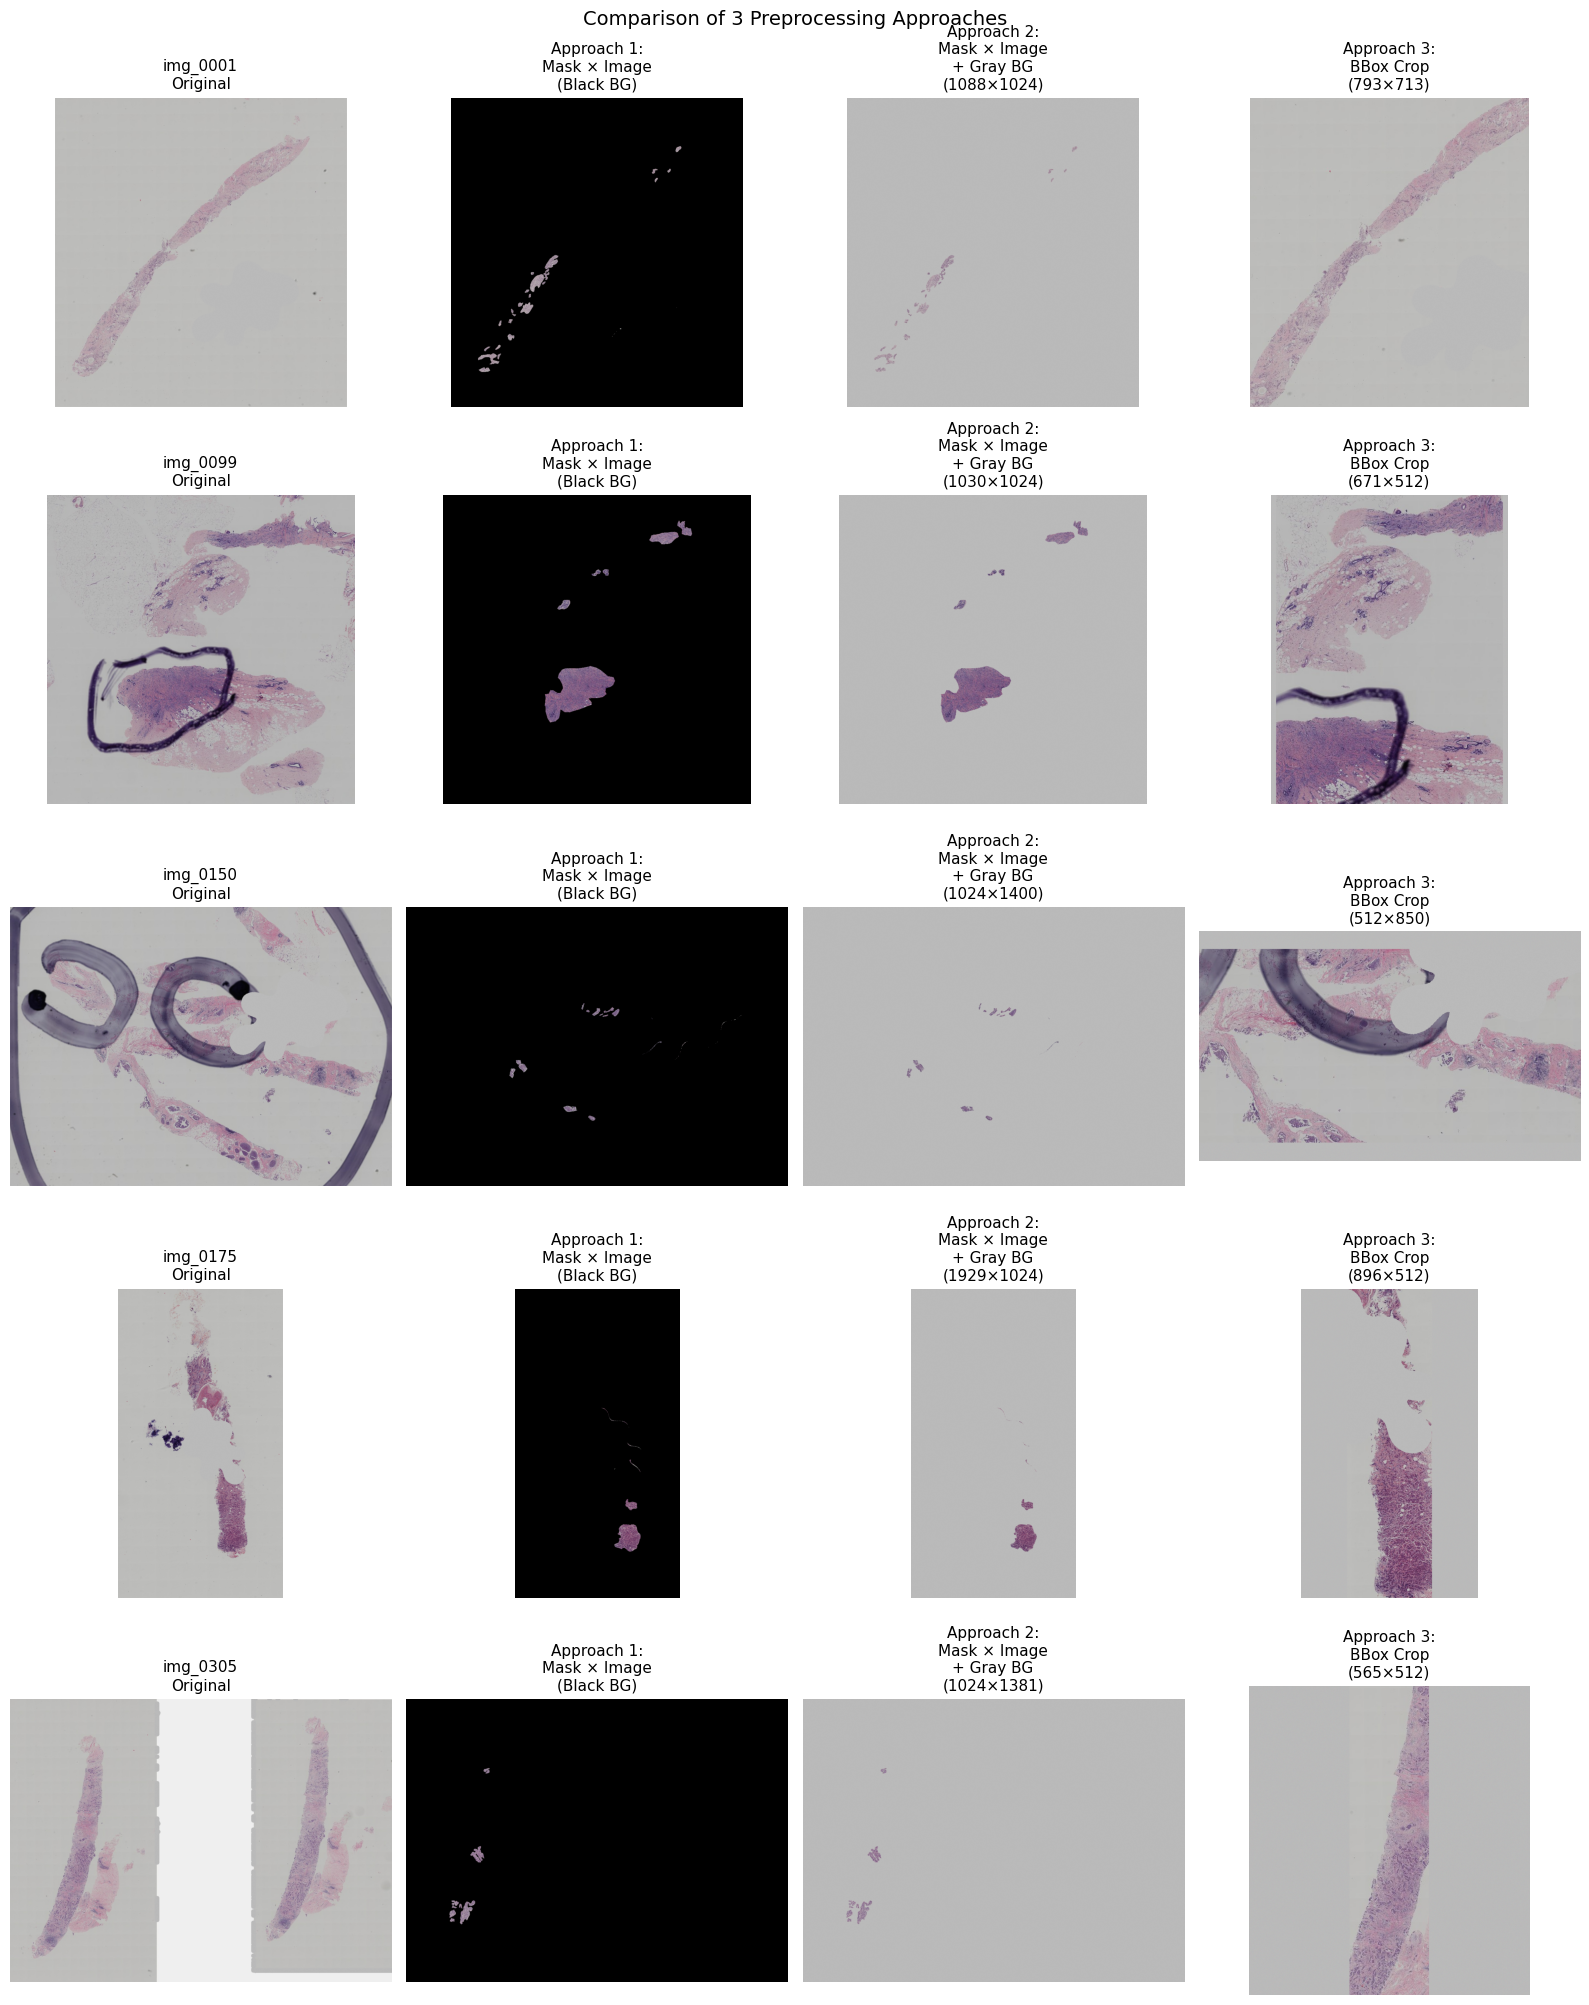


✓ Visualization complete

Approach Summary:
1. Black Background: Clean but may confuse model (black != natural background)
2. Gray Background: More natural, similar to actual tissue background
3. BBox Crop: Preserves all tissue, but image sizes vary (requires resize)


In [ ]:
from pathlib import Path
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Test with images from data_cleaned_no_stains
test_dir = Path('data_cleaned_no_stains/train_data')

# Select a few test images
test_ids = ['0001', '0099', '0150', '0175', '0305']

def apply_mask_black_bg(img, mask):
    """Approach 1: Mask × Image (black background)"""
    # Ensure mask is binary
    mask_binary = (mask > 0).astype(np.uint8)
    # Apply mask to each channel
    result = img.copy()
    for c in range(3):
        result[:, :, c] = img[:, :, c] * mask_binary
    return result

def apply_mask_gray_bg(img, mask):
    """Approach 2: Mask × Image + Gray fill background with noise"""
    # First apply mask (black background)
    mask_binary = (mask > 0).astype(np.uint8)
    result = apply_mask_black_bg(img, mask)

    # Create gray background with noise
    base_gray = 186
    noise = np.random.randint(-2, 3, size=mask.shape, dtype=np.int16)
    gray_with_noise = np.clip(base_gray + noise, 0, 255).astype(np.uint8)

    # Fill background (where mask is 0)
    background_mask = mask_binary == 0
    for c in range(3):
        result[:, :, c][background_mask] = gray_with_noise[background_mask]

    return result

def crop_by_bbox(img, mask):
    """Approach 3: Crop by mask bounding box with padding to 512×512 minimum"""
    # Find bounding box of mask
    mask_binary = mask > 0
    rows = np.any(mask_binary, axis=1)
    cols = np.any(mask_binary, axis=0)

    if not rows.any() or not cols.any():
        return img  # Return original if mask is empty

    y_min, y_max = np.where(rows)[0][[0, -1]]
    x_min, x_max = np.where(cols)[0][[0, -1]]

    # Crop image
    cropped = img[y_min:y_max+1, x_min:x_max+1]

    # Pad to at least 512×512 if needed
    h, w = cropped.shape[:2]
    target_h = max(h, 512)
    target_w = max(w, 512)

    if h < target_h or w < target_w:
        # Calculate padding amounts
        pad_top = (target_h - h) // 2
        pad_bottom = target_h - h - pad_top
        pad_left = (target_w - w) // 2
        pad_right = target_w - w - pad_left

        # Create gray background with noise
        base_gray = 186
        padded = np.zeros((target_h, target_w, 3), dtype=np.uint8)

        # Fill with gray + noise
        for c in range(3):
            noise = np.random.randint(-2, 3, size=(target_h, target_w), dtype=np.int16)
            padded[:, :, c] = np.clip(base_gray + noise, 0, 255).astype(np.uint8)

        # Place cropped image in center
        padded[pad_top:pad_top+h, pad_left:pad_left+w] = cropped

        return padded

    return cropped

# Visualize all three approaches
n_imgs = min(len(test_ids), 5)
fig, axes = plt.subplots(n_imgs, 4, figsize=(16, n_imgs * 4))

if n_imgs == 1:
    axes = axes.reshape(1, -1)

for i, img_id in enumerate(test_ids[:n_imgs]):
    img_path = test_dir / f'img_{img_id}.png'
    mask_path = test_dir / f'mask_{img_id}.png'

    if not img_path.exists() or not mask_path.exists():
        print(f"Warning: img_{img_id} or its mask not found")
        continue

    # Load image and mask
    img = np.array(Image.open(img_path))
    mask = np.array(Image.open(mask_path))

    if mask.ndim == 3:
        mask = mask[:, :, 0]

    # Apply all three approaches
    result1 = apply_mask_black_bg(img, mask)
    result2 = apply_mask_gray_bg(img, mask)
    result3 = crop_by_bbox(img, mask)

    # Display original
    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f'img_{img_id}\nOriginal', fontsize=11)
    axes[i, 0].axis('off')

    # Display approach 1: Black background
    axes[i, 1].imshow(result1)
    axes[i, 1].set_title('Approach 1:\nMask × Image\n(Black BG)', fontsize=11)
    axes[i, 1].axis('off')

    # Display approach 2: Gray background
    axes[i, 2].imshow(result2)
    axes[i, 2].set_title(f'Approach 2:\nMask × Image\n+ Gray BG\n({result2.shape[0]}×{result2.shape[1]})', fontsize=11)
    axes[i, 2].axis('off')

    # Display approach 3: Cropped
    axes[i, 3].imshow(result3)
    axes[i, 3].set_title(f'Approach 3:\nBBox Crop\n({result3.shape[0]}×{result3.shape[1]})', fontsize=11)
    axes[i, 3].axis('off')

plt.tight_layout()
plt.suptitle('Comparison of 3 Preprocessing Approaches', fontsize=14, y=1.00)
plt.show()

print("\n✓ Visualization complete")
print("\nApproach Summary:")
print("1. Black Background: Clean but may confuse model (black != natural background)")
print("2. Gray Background: More natural, similar to actual tissue background")
print("3. BBox Crop: Preserves all tissue, but image sizes vary (requires resize)")

In [ ]:
# Apply Approach 3 (BBox Crop with 512x512 padding) to all images and save to bbox_data_cleaned
from pathlib import Path
import numpy as np
from PIL import Image

source_dir = Path('data_cleaned_no_stains/train_data')
output_dir = Path('bbox_data_cleaned')
output_train_dir = output_dir / 'train_data'
output_train_dir.mkdir(parents=True, exist_ok=True)

print("Applying Approach 3 (BBox Crop + 512×512 Padding) to all images...\n")

def crop_by_bbox_with_mask(img, mask):
    """Crop both image and mask by bbox with padding to 512×512 minimum"""
    # Find bounding box of mask
    mask_binary = mask > 0
    rows = np.any(mask_binary, axis=1)
    cols = np.any(mask_binary, axis=0)

    if not rows.any() or not cols.any():
        # Empty mask - return original
        return img, mask

    y_min, y_max = np.where(rows)[0][[0, -1]]
    x_min, x_max = np.where(cols)[0][[0, -1]]

    # Crop both image and mask
    cropped_img = img[y_min:y_max+1, x_min:x_max+1]
    cropped_mask = mask[y_min:y_max+1, x_min:x_max+1]

    # Pad to at least 512×512 if needed
    h, w = cropped_img.shape[:2]
    target_h = max(h, 512)
    target_w = max(w, 512)

    if h < target_h or w < target_w:
        # Calculate padding amounts
        pad_top = (target_h - h) // 2
        pad_bottom = target_h - h - pad_top
        pad_left = (target_w - w) // 2
        pad_right = target_w - w - pad_left

        # Pad image with gray background + noise
        base_gray = 186
        padded_img = np.zeros((target_h, target_w, 3), dtype=np.uint8)

        for c in range(3):
            noise = np.random.randint(-2, 3, size=(target_h, target_w), dtype=np.int16)
            padded_img[:, :, c] = np.clip(base_gray + noise, 0, 255).astype(np.uint8)

        # Place cropped image in center
        padded_img[pad_top:pad_top+h, pad_left:pad_left+w] = cropped_img

        # Pad mask with zeros
        padded_mask = np.zeros((target_h, target_w), dtype=mask.dtype)
        padded_mask[pad_top:pad_top+h, pad_left:pad_left+w] = cropped_mask

        return padded_img, padded_mask

    return cropped_img, cropped_mask

processed_count = 0

for img_path in sorted(source_dir.glob('img_*.png')):
    img_id = img_path.stem.split('_')[1]
    mask_path = source_dir / f'mask_{img_id}.png'

    if not mask_path.exists():
        print(f"Warning: mask not found for {img_path.name}, skipping...")
        continue

    # Load image and mask
    img = np.array(Image.open(img_path))
    mask = np.array(Image.open(mask_path))

    if mask.ndim == 3:
        mask = mask[:, :, 0]

    # Apply approach 3
    img_processed, mask_processed = crop_by_bbox_with_mask(img, mask)

    # Save processed image and mask
    Image.fromarray(img_processed).save(output_train_dir / f'img_{img_id}.png')
    Image.fromarray(mask_processed).save(output_train_dir / f'mask_{img_id}.png')

    processed_count += 1

    if processed_count % 50 == 0:
        print(f"Processed {processed_count} images...")

print(f"\n{'='*60}")
print(f"Processing complete!")
print(f"{'='*60}")
print(f"Total images processed: {processed_count}")
print(f"Output directory: {output_train_dir}")
print(f"{'='*60}")

Applying Approach 3 (BBox Crop + 512×512 Padding) to all images...

Processed 50 images...
Processed 100 images...
Processed 150 images...
Processed 200 images...
Processed 250 images...
Processed 300 images...
Processed 350 images...
Processed 400 images...
Processed 450 images...
Processed 500 images...
Processed 550 images...
Processed 600 images...

Processing complete!
Total images processed: 631
Output directory: bbox_data_cleaned\train_data


In [ ]:
# Copy train_labels.csv and test_data to bbox_data_cleaned directory
import shutil
from pathlib import Path

source_dir = Path('data_cleaned_no_stains')
output_dir = Path('bbox_data_cleaned')

# Copy train_labels.csv
labels_src = source_dir / 'train_labels.csv'
labels_dst = output_dir / 'train_labels.csv'

if labels_src.exists():
    shutil.copy2(labels_src, labels_dst)
    print(f"✓ Copied train_labels.csv")
else:
    print("⚠ train_labels.csv not found")

# Copy test_data directory
test_src = source_dir / 'test_data'
test_dst = output_dir / 'test_data'

if test_src.exists():
    if test_dst.exists():
        shutil.rmtree(test_dst)
    shutil.copytree(test_src, test_dst)

    # Count files
    test_files = len(list(test_dst.glob('img_*.png')))
    print(f"✓ Copied test_data directory ({test_files} images)")
else:
    print("⚠ test_data directory not found")

print(f"\n{'='*60}")
print(f"Complete dataset ready at: {output_dir}/")
print(f"  - train_data/ (with Approach 3 applied)")
print(f"  - test_data/ (copied as-is)")
print(f"  - train_labels.csv")
print(f"{'='*60}")

✓ Copied train_labels.csv
✓ Copied test_data directory (477 images)

Complete dataset ready at: bbox_data_cleaned/
  - train_data/ (with Approach 3 applied)
  - test_data/ (copied as-is)
  - train_labels.csv


In [ ]:
# Apply Approach 2 (Mask × Image + Gray BG) to all images and save to masked_data
from pathlib import Path
import numpy as np
from PIL import Image

source_dir = Path('data_cleaned_no_stains/train_data')
output_dir = Path('masked_data')
output_train_dir = output_dir / 'train_data'
output_train_dir.mkdir(parents=True, exist_ok=True)

print("Applying Approach 2 (Mask × Image + Gray Background) to all images...\n")

def apply_mask_gray_bg(img, mask):
    """Apply mask with gray background fill"""
    mask_binary = (mask > 0).astype(np.uint8)
    result = img.copy()

    # Apply mask to each channel
    for c in range(3):
        result[:, :, c] = img[:, :, c] * mask_binary

    # Create gray background with noise
    base_gray = 186
    noise = np.random.randint(-2, 3, size=mask.shape, dtype=np.int16)
    gray_with_noise = np.clip(base_gray + noise, 0, 255).astype(np.uint8)

    # Fill background (where mask is 0)
    background_mask = mask_binary == 0
    for c in range(3):
        result[:, :, c][background_mask] = gray_with_noise[background_mask]

    return result

processed_count = 0

for img_path in sorted(source_dir.glob('img_*.png')):
    img_id = img_path.stem.split('_')[1]
    mask_path = source_dir / f'mask_{img_id}.png'

    if not mask_path.exists():
        print(f"Warning: mask not found for {img_path.name}, skipping...")
        continue

    # Load image and mask
    img = np.array(Image.open(img_path))
    mask = np.array(Image.open(mask_path))

    if mask.ndim == 3:
        mask = mask[:, :, 0]

    # Apply approach 2
    img_masked = apply_mask_gray_bg(img, mask)

    # Save processed image (we don't need to save mask since it's already in the source)
    Image.fromarray(img_masked).save(output_train_dir / f'img_{img_id}.png')

    # Copy mask as-is for reference
    Image.fromarray(mask).save(output_train_dir / f'mask_{img_id}.png')

    processed_count += 1

    if processed_count % 50 == 0:
        print(f"Processed {processed_count} images...")

print(f"\n{'='*60}")
print(f"Processing complete!")
print(f"{'='*60}")
print(f"Total images processed: {processed_count}")
print(f"Output directory: {output_train_dir}")
print(f"{'='*60}")

Applying Approach 2 (Mask × Image + Gray Background) to all images...

Processed 50 images...
Processed 100 images...
Processed 150 images...
Processed 200 images...
Processed 250 images...
Processed 300 images...
Processed 350 images...
Processed 400 images...
Processed 450 images...
Processed 500 images...
Processed 550 images...
Processed 600 images...

Processing complete!
Total images processed: 631
Output directory: masked_data\train_data


In [ ]:
# Copy train_labels.csv and test_data to masked_data directory
import shutil
from pathlib import Path

source_dir = Path('data_cleaned_no_stains')
output_dir = Path('masked_data')

# Copy train_labels.csv
labels_src = source_dir / 'train_labels.csv'
labels_dst = output_dir / 'train_labels.csv'

if labels_src.exists():
    shutil.copy2(labels_src, labels_dst)
    print(f"✓ Copied train_labels.csv")
else:
    print("⚠ train_labels.csv not found")

# Copy test_data directory
test_src = source_dir / 'test_data'
test_dst = output_dir / 'test_data'

if test_src.exists():
    if test_dst.exists():
        shutil.rmtree(test_dst)
    shutil.copytree(test_src, test_dst)

    # Count files
    test_files = len(list(test_dst.glob('img_*.png')))
    print(f"✓ Copied test_data directory ({test_files} images)")
else:
    print("⚠ test_data directory not found")

print(f"\n{'='*60}")
print(f"Complete dataset ready at: {output_dir}/")
print(f"  - train_data/ (with Approach 2 applied)")
print(f"  - test_data/ (copied as-is)")
print(f"  - train_labels.csv")
print(f"{'='*60}")

✓ Copied train_labels.csv
✓ Copied test_data directory (477 images)

Complete dataset ready at: masked_data/
  - train_data/ (with Approach 2 applied)
  - test_data/ (copied as-is)
  - train_labels.csv


# ROI-guided 224x224 tiling


In [ ]:
from pathlib import Path
import numpy as np
from PIL import Image
from skimage.measure import label, regionprops
from skimage.color import rgb2hed, hed2rgb
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Config
TILE_SIZE = 224
MIN_TILES = 2
MAX_TILES = 10
STRIDE = 64  # allow overlap

root = Path('bbox_data_cleaned/train_data/')
tiles_dir = Path('bbox_data_cleaned/train_tiles/')

tiles_dir.mkdir(exist_ok=True)

In [ ]:
def clamp(v, upper):
    upper = int(upper)
    return int(max(0, min(v, upper)))


def add_candidate(candidates, y, x, h, w):
    candidates.add((clamp(y, h - TILE_SIZE), clamp(x, w - TILE_SIZE)))


def generate_candidates(mask):
    h, w = mask.shape
    ys, xs = np.nonzero(mask)
    if len(ys) == 0:
        return []
    y_min, y_max = ys.min(), ys.max()
    x_min, x_max = xs.min(), xs.max()
    candidates = set()
    add = lambda y, x: add_candidate(candidates, y, x, h, w)
    # overall ROI box corners + center
    add(y_min, x_min)
    add(y_min, x_max - TILE_SIZE)
    add(y_max - TILE_SIZE, x_min)
    add(y_max - TILE_SIZE, x_max - TILE_SIZE)
    add((y_min + y_max) // 2 - TILE_SIZE // 2, (x_min + x_max) // 2 - TILE_SIZE // 2)
    # coarse grid across ROI box
    y_start = max(0, y_min - TILE_SIZE)
    y_end = min(y_max, h - TILE_SIZE)
    x_start = max(0, x_min - TILE_SIZE)
    x_end = min(x_max, w - TILE_SIZE)
    for y in range(y_start, y_end + 1, STRIDE):
        for x in range(x_start, x_end + 1, STRIDE):
            add(y, x)
    # per-component anchors
    lbl = label(mask)
    for r in regionprops(lbl):
        minr, minc, maxr, maxc = r.bbox
        add(minr, minc)
        add(maxr - TILE_SIZE, minc)
        add(minr, maxc - TILE_SIZE)
        add(maxr - TILE_SIZE, maxc - TILE_SIZE)
        add((minr + maxr) // 2 - TILE_SIZE // 2, (minc + maxc) // 2 - TILE_SIZE // 2)
    return list(candidates)


def choose_tiles(mask):
    candidates = generate_candidates(mask)
    if not candidates:
        return []
    covered = np.zeros_like(mask, dtype=bool)
    selected = []
    used = set()
    for i in range(MAX_TILES):
        best = None
        best_gain = -1
        best_total = -1
        for y, x in candidates:
            if (y, x) in used:
                continue
            patch = mask[y:y+TILE_SIZE, x:x+TILE_SIZE]
            gain = np.logical_and(patch, ~covered[y:y+TILE_SIZE, x:x+TILE_SIZE]).sum()
            total = patch.sum()
            if gain > best_gain or (gain == best_gain and total > best_total):
                best_gain = gain
                best_total = total
                best = (y, x)
        if best is None:
            break
        if best_gain == 0 and i >= MIN_TILES:
            break
        selected.append(best)
        y, x = best
        covered[y:y+TILE_SIZE, x:x+TILE_SIZE] |= mask[y:y+TILE_SIZE, x:x+TILE_SIZE]
        used.add(best)
    if len(selected) < MIN_TILES:
        remaining = sorted(
            [c for c in candidates if c not in used],
            key=lambda c: mask[c[0]:c[0]+TILE_SIZE, c[1]:c[1]+TILE_SIZE].sum(),
            reverse=True,
        )
        for c in remaining:
            if len(selected) >= MIN_TILES:
                break
            selected.append(c)
    return selected[:MAX_TILES]


In [ ]:
def process_image(img_path):
    idx = img_path.stem.split('_')[1]
    mask_path = root / f'mask_{idx}.png'
    if not mask_path.exists():
        print(f'Missing mask for {img_path.name}, skipping.')
        return 0
    mask = np.array(Image.open(mask_path))
    if mask.ndim == 3:
        mask = mask[..., 0]
    mask_bool = mask > 0
    if mask_bool.sum() == 0:
        print(f'{mask_path.name} empty ROI, skipping.')
        return 0
    tiles = choose_tiles(mask_bool)
    if not tiles:
        print(f'No tiles chosen for {img_path.name}')
        return 0
    image = np.array(Image.open(img_path))
    saved = 0
    for i, (y, x) in enumerate(tiles, 1):
        img_tile = image[y:y+TILE_SIZE, x:x+TILE_SIZE]
        mask_tile = (mask_bool[y:y+TILE_SIZE, x:x+TILE_SIZE] * 255).astype(np.uint8)
        Image.fromarray(img_tile).save(tiles_dir / f'{img_path.stem}_tile_{i:02d}.png')
        Image.fromarray(mask_tile).save(tiles_dir / f'mask_{idx}_tile_{i:02d}.png')
        saved += 1
    print(f'{img_path.name}: saved {saved} tiles.')
    return saved


def process_all_images():
    total_tiles = 0
    for img_path in sorted(root.glob('img_*.png')):
        total_tiles += process_image(img_path)
    print(f'Total tiles saved: {total_tiles}')

# Run process_all_images() after visualizing tiles to ensure coverage is good

In [ ]:
process_all_images()

img_0000.png: saved 4 tiles.
img_0001.png: saved 5 tiles.
img_0002.png: saved 6 tiles.
img_0003.png: saved 2 tiles.
img_0004.png: saved 2 tiles.
img_0006.png: saved 4 tiles.
img_0007.png: saved 5 tiles.
img_0009.png: saved 5 tiles.
img_0010.png: saved 4 tiles.
img_0011.png: saved 4 tiles.
img_0012.png: saved 8 tiles.
img_0013.png: saved 4 tiles.
img_0014.png: saved 4 tiles.
img_0015.png: saved 4 tiles.
img_0016.png: saved 7 tiles.
img_0017.png: saved 7 tiles.
img_0018.png: saved 10 tiles.
img_0019.png: saved 3 tiles.
img_0020.png: saved 6 tiles.
img_0021.png: saved 2 tiles.
img_0023.png: saved 5 tiles.
img_0024.png: saved 7 tiles.
img_0025.png: saved 2 tiles.
img_0026.png: saved 4 tiles.
img_0028.png: saved 9 tiles.
img_0029.png: saved 4 tiles.
img_0030.png: saved 3 tiles.
img_0031.png: saved 10 tiles.
img_0032.png: saved 4 tiles.
img_0033.png: saved 3 tiles.
img_0034.png: saved 5 tiles.
img_0035.png: saved 2 tiles.
img_0037.png: saved 3 tiles.
img_0038.png: saved 4 tiles.
img_0039.png

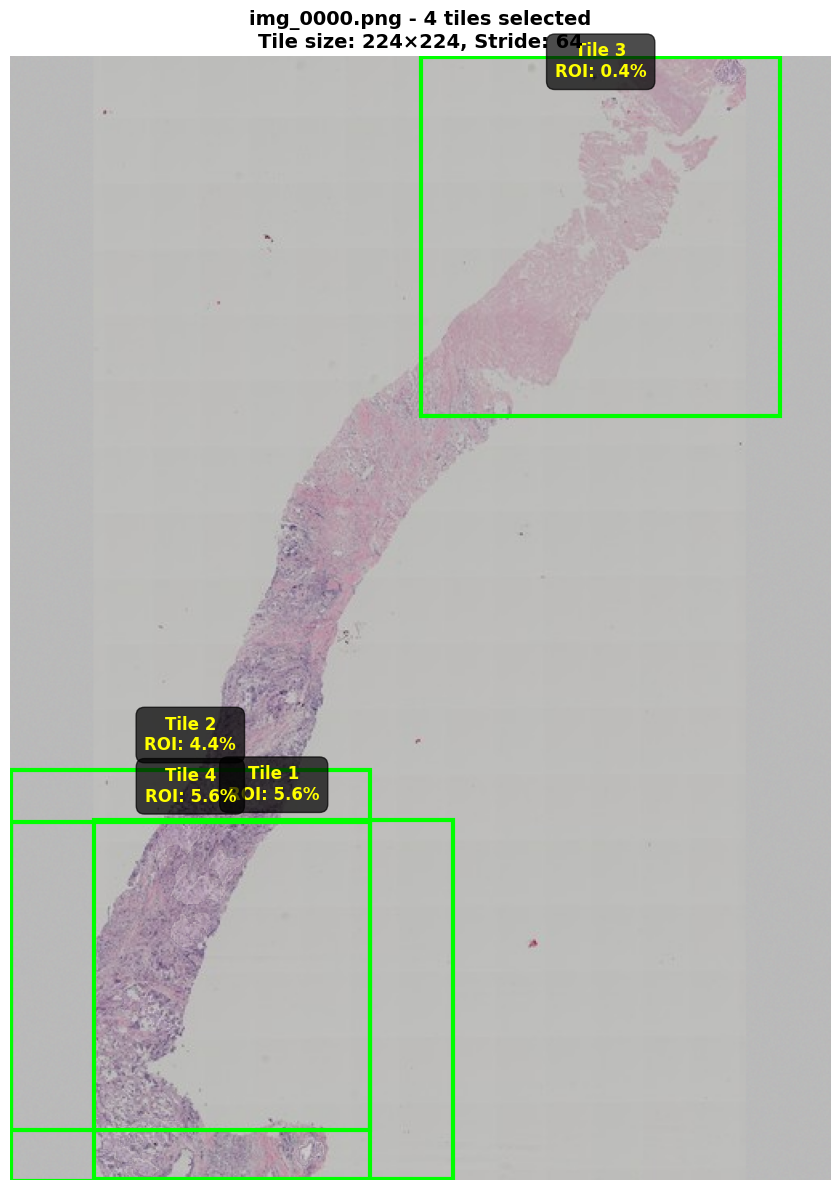

img_0000.png:
  Tile 1: Position (52, 476), ROI Coverage: 5.6%
  Tile 2: Position (0, 445), ROI Coverage: 4.4%
  Tile 3: Position (256, 0), ROI Coverage: 0.4%
  Tile 4: Position (0, 477), ROI Coverage: 5.6%



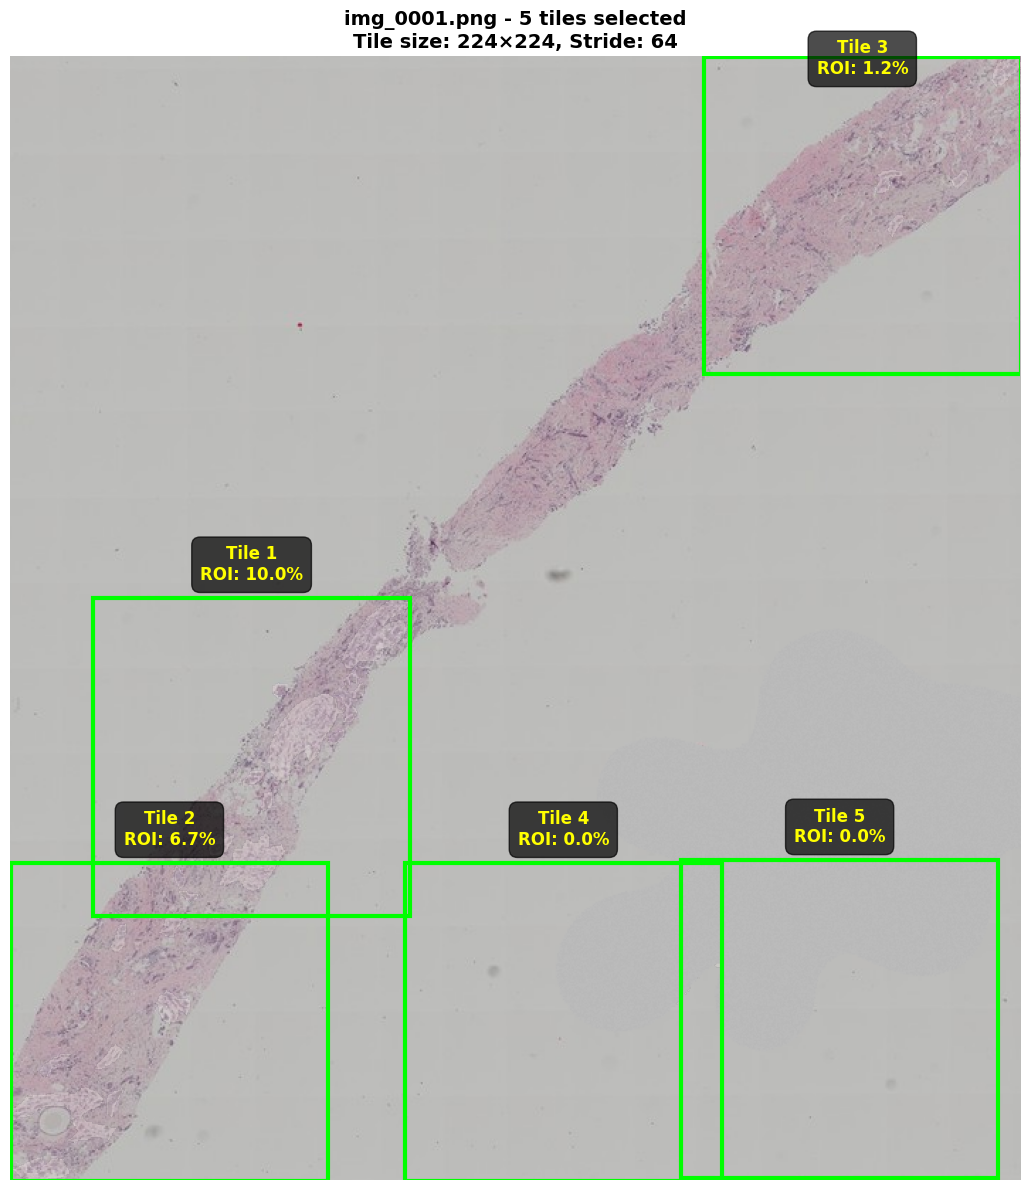

img_0001.png:
  Tile 1: Position (58, 382), ROI Coverage: 10.0%
  Tile 2: Position (0, 569), ROI Coverage: 6.7%
  Tile 3: Position (489, 0), ROI Coverage: 1.2%
  Tile 4: Position (278, 569), ROI Coverage: 0.0%
  Tile 5: Position (473, 567), ROI Coverage: 0.0%



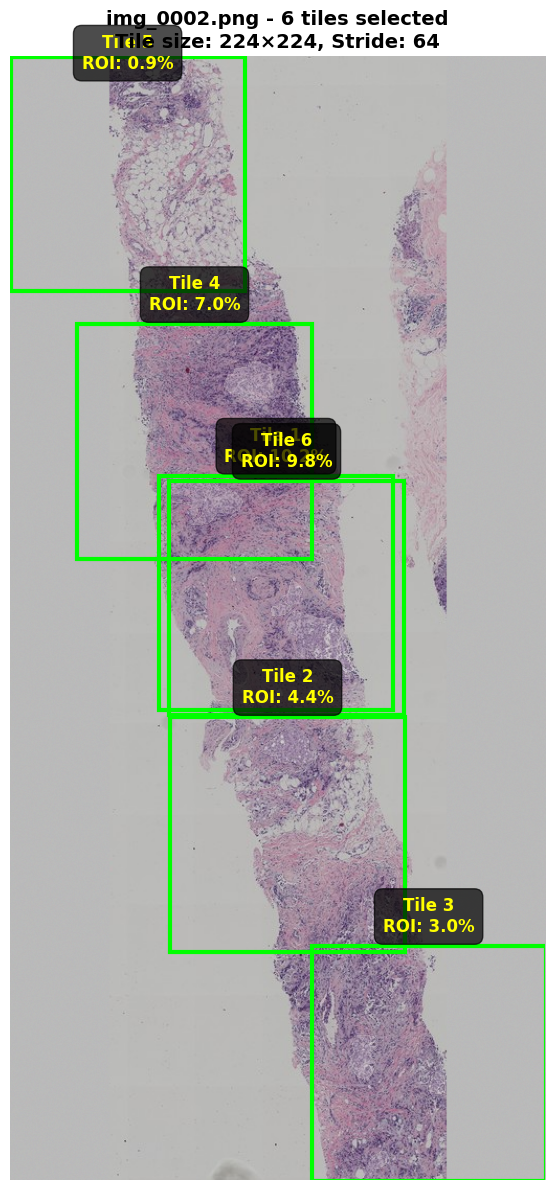

img_0002.png:
  Tile 1: Position (142, 401), ROI Coverage: 10.2%
  Tile 2: Position (153, 632), ROI Coverage: 4.4%
  Tile 3: Position (288, 851), ROI Coverage: 3.0%
  Tile 4: Position (64, 256), ROI Coverage: 7.0%
  Tile 5: Position (0, 0), ROI Coverage: 0.9%
  Tile 6: Position (152, 406), ROI Coverage: 9.8%

Visualized 3 image(s)


In [ ]:
# Visualize tile positions with ROI coverage on sample images
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt

def visualize_tiles_with_coverage(img_ids=None, max_examples=5):
    """Visualize tile positions with ROI coverage percentages"""
    count = 0
    for img_path in sorted(root.glob('img_*.png')):
        idx = img_path.stem.split('_')[1]

        # Filter by specific IDs if provided
        if img_ids and idx not in img_ids:
            continue

        mask_path = root / f'mask_{idx}.png'
        if not mask_path.exists():
            continue

        # Load image and mask
        img = np.array(Image.open(img_path))
        mask = np.array(Image.open(mask_path))
        if mask.ndim == 3:
            mask = mask[:, :, 0]
        mask_bool = mask > 0

        if mask_bool.sum() == 0:
            continue

        # Get tile positions
        tiles = choose_tiles(mask_bool)
        if not tiles:
            continue

        # Create visualization
        fig, ax = plt.subplots(figsize=(12, 12))
        ax.imshow(img)

        # Overlay mask with transparency
        ax.imshow(np.ma.masked_where(~mask_bool, mask_bool), cmap='Reds', alpha=0.25)

        # Draw tiles and calculate coverage
        for tile_idx, (y, x) in enumerate(tiles, 1):
            # Calculate ROI coverage for this tile
            tile_mask = mask_bool[y:y+TILE_SIZE, x:x+TILE_SIZE]
            roi_coverage = (tile_mask.sum() / (TILE_SIZE * TILE_SIZE)) * 100

            # Draw tile rectangle
            rect = Rectangle((x, y), TILE_SIZE, TILE_SIZE,
                            linewidth=3, edgecolor='lime', facecolor='none')
            ax.add_patch(rect)

            # Add tile number and ROI coverage text above the tile
            text_y = max(y - 10, 15)  # Position above tile, but not off-screen
            ax.text(x + TILE_SIZE // 2, text_y,
                   f'Tile {tile_idx}\nROI: {roi_coverage:.1f}%',
                   color='yellow', fontsize=12, fontweight='bold',
                   ha='center', va='bottom',
                   bbox=dict(boxstyle='round,pad=0.5', facecolor='black', alpha=0.7))

        ax.set_title(f'img_{idx}.png - {len(tiles)} tiles selected\n'
                    f'Tile size: {TILE_SIZE}×{TILE_SIZE}, Stride: {STRIDE}',
                    fontsize=14, fontweight='bold')
        ax.axis('off')

        plt.tight_layout()
        plt.show()

        # Print summary
        print(f"img_{idx}.png:")
        for tile_idx, (y, x) in enumerate(tiles, 1):
            tile_mask = mask_bool[y:y+TILE_SIZE, x:x+TILE_SIZE]
            roi_coverage = (tile_mask.sum() / (TILE_SIZE * TILE_SIZE)) * 100
            print(f"  Tile {tile_idx}: Position ({x}, {y}), ROI Coverage: {roi_coverage:.1f}%")
        print()

        count += 1
        if count >= max_examples:
            break

    print(f"Visualized {count} image(s)")

# Visualize a few examples
visualize_tiles_with_coverage(max_examples=3)

# Connected components Tile Selection Approach

Find tile positions using kernel-based approach to cover all white islands in the mask.

In [ ]:
import cv2
from scipy import ndimage
from scipy.spatial.distance import cdist

def choose_tiles_kernel_based(mask):
    """
    Use kernel-based approach to find tile positions covering all white islands.
    Ensures ALL components are covered by clustering centroids based on distance.

    Args:
        mask: Binary mask (boolean array)

    Returns:
        List of (y, x) tile positions
    """
    if mask.sum() == 0:
        return []

    h, w = mask.shape
    mask_uint8 = mask.astype(np.uint8) * 255

    # Find connected components (islands) in the mask
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(mask_uint8, connectivity=8)

    # Collect all valid component centroids (skip background at index 0, skip tiny noise)
    valid_centroids = []
    for comp_idx in range(1, num_labels):
        area = stats[comp_idx, cv2.CC_STAT_AREA]
        if area >= 100:  # Skip tiny noise
            cx, cy = centroids[comp_idx]
            valid_centroids.append((cy, cx, comp_idx))  # (y, x, index)

    if not valid_centroids:
        return []

    print(f"Found {len(valid_centroids)} components to cover")

    # Strategy: Greedily place tiles to cover all centroids
    # Each tile should cover as many uncovered centroids as possible
    selected_tiles = []
    covered_components = set()

    while len(covered_components) < len(valid_centroids) and len(selected_tiles) < MAX_TILES:
        # Find uncovered centroids
        uncovered = [c for i, c in enumerate(valid_centroids) if i not in covered_components]

        if not uncovered:
            break

        # Try different tile positions and score them by:
        # 1. How many uncovered centroids they capture
        # 2. Total ROI coverage
        best_tile = None
        best_score = (-1, 0)  # (num_centroids, roi_coverage)

        # Generate candidate tile positions around each uncovered centroid
        candidates = set()
        for cy, cx, _ in uncovered:
            # Center tile on this centroid
            tile_y = int(max(0, min(cy - TILE_SIZE // 2, h - TILE_SIZE)))
            tile_x = int(max(0, min(cx - TILE_SIZE // 2, w - TILE_SIZE)))
            candidates.add((tile_y, tile_x))

            # Add slight variations to catch nearby components
            for dy in [-TILE_SIZE // 4, 0, TILE_SIZE // 4]:
                for dx in [-TILE_SIZE // 4, 0, TILE_SIZE // 4]:
                    tile_y_var = int(max(0, min(tile_y + dy, h - TILE_SIZE)))
                    tile_x_var = int(max(0, min(tile_x + dx, w - TILE_SIZE)))
                    candidates.add((tile_y_var, tile_x_var))

        # Score each candidate
        for tile_y, tile_x in candidates:
            # Count how many uncovered centroids this tile would cover
            centroids_covered = 0
            covered_indices = []

            for i, (cy, cx, comp_idx) in enumerate(valid_centroids):
                if i in covered_components:
                    continue

                # Check if centroid is within this tile
                if tile_y <= cy < tile_y + TILE_SIZE and tile_x <= cx < tile_x + TILE_SIZE:
                    centroids_covered += 1
                    covered_indices.append(i)

            # Calculate ROI coverage as tiebreaker
            tile_mask = mask[tile_y:tile_y+TILE_SIZE, tile_x:tile_x+TILE_SIZE]
            roi_coverage = tile_mask.sum()

            score = (centroids_covered, roi_coverage)

            if score > best_score:
                best_score = score
                best_tile = (tile_y, tile_x, covered_indices)

        if best_tile is None:
            break

        tile_y, tile_x, covered_indices = best_tile
        selected_tiles.append((tile_y, tile_x))
        covered_components.update(covered_indices)

        print(f"Tile {len(selected_tiles)}: covers {len(covered_indices)} components, "
              f"total covered: {len(covered_components)}/{len(valid_centroids)}")

    # Ensure we have minimum tiles if needed
    if len(selected_tiles) < MIN_TILES:
        # Add tiles at mask center of mass
        cy, cx = ndimage.center_of_mass(mask)
        cy, cx = int(cy), int(cx)

        for offset in range(MIN_TILES - len(selected_tiles)):
            tile_y = int(max(0, min(cy - TILE_SIZE // 2 + offset * STRIDE, h - TILE_SIZE)))
            tile_x = int(max(0, min(cx - TILE_SIZE // 2 + offset * STRIDE, w - TILE_SIZE)))

            if (tile_y, tile_x) not in selected_tiles:
                selected_tiles.append((tile_y, tile_x))

    print(f"Final: {len(selected_tiles)} tiles covering {len(covered_components)}/{len(valid_centroids)} components")

    return selected_tiles[:MAX_TILES]


# Test the kernel-based approach
print("Testing kernel-based tile selection...")
test_img_path = next(root.glob('img_*.png'))
test_idx = test_img_path.stem.split('_')[1]
test_mask_path = root / f'mask_{test_idx}.png'

if test_mask_path.exists():
    test_mask = np.array(Image.open(test_mask_path))
    if test_mask.ndim == 3:
        test_mask = test_mask[:, :, 0]
    test_mask_bool = test_mask > 0

    kernel_tiles = choose_tiles_kernel_based(test_mask_bool)
    roi_tiles = choose_tiles(test_mask_bool)

    print(f"\nTest image: img_{test_idx}.png")
    print(f"Kernel-based approach: {len(kernel_tiles)} tiles")
    print(f"ROI-based approach: {len(roi_tiles)} tiles")
else:
    print("Test mask not found")

Testing kernel-based tile selection...
Found 10 components to cover
Tile 1: covers 9 components, total covered: 9/10
Tile 2: covers 1 components, total covered: 10/10
Final: 2 tiles covering 10/10 components

Test image: img_0000.png
Kernel-based approach: 2 tiles
ROI-based approach: 2 tiles


In [ ]:
# Compare kernel-based vs ROI-based approaches visually
def compare_tiling_approaches(img_ids=None, max_examples=3):
    """Compare kernel-based and ROI-based tiling approaches"""
    count = 0
    for img_path in sorted(root.glob('img_*.png')):
        idx = img_path.stem.split('_')[1]

        if img_ids and idx not in img_ids:
            continue

        mask_path = root / f'mask_{idx}.png'
        if not mask_path.exists():
            continue

        # Load image and mask
        img = np.array(Image.open(img_path))
        mask = np.array(Image.open(mask_path))
        if mask.ndim == 3:
            mask = mask[:, :, 0]
        mask_bool = mask > 0

        if mask_bool.sum() == 0:
            continue

        # Get tiles from both approaches
        kernel_tiles = choose_tiles_kernel_based(mask_bool)
        roi_tiles = choose_tiles(mask_bool)

        if not kernel_tiles and not roi_tiles:
            continue

        # Create side-by-side visualization
        fig, axes = plt.subplots(1, 2, figsize=(24, 12))

        # Left: Kernel-based approach
        axes[0].imshow(img)
        axes[0].imshow(np.ma.masked_where(~mask_bool, mask_bool), cmap='Reds', alpha=0.25)

        for tile_idx, (y, x) in enumerate(kernel_tiles, 1):
            tile_mask = mask_bool[y:y+TILE_SIZE, x:x+TILE_SIZE]
            roi_coverage = (tile_mask.sum() / (TILE_SIZE * TILE_SIZE)) * 100

            rect = Rectangle((x, y), TILE_SIZE, TILE_SIZE,
                            linewidth=3, edgecolor='lime', facecolor='none')
            axes[0].add_patch(rect)

            text_y = max(y - 10, 15)
            axes[0].text(x + TILE_SIZE // 2, text_y,
                        f'K{tile_idx}\n{roi_coverage:.1f}%',
                        color='yellow', fontsize=10, fontweight='bold',
                        ha='center', va='bottom',
                        bbox=dict(boxstyle='round,pad=0.5', facecolor='black', alpha=0.7))

        axes[0].set_title(f'Kernel-based: {len(kernel_tiles)} tiles\nCovers all mask islands',
                         fontsize=14, fontweight='bold')
        axes[0].axis('off')

        # Right: ROI-based approach
        axes[1].imshow(img)
        axes[1].imshow(np.ma.masked_where(~mask_bool, mask_bool), cmap='Reds', alpha=0.25)

        for tile_idx, (y, x) in enumerate(roi_tiles, 1):
            tile_mask = mask_bool[y:y+TILE_SIZE, x:x+TILE_SIZE]
            roi_coverage = (tile_mask.sum() / (TILE_SIZE * TILE_SIZE)) * 100

            rect = Rectangle((x, y), TILE_SIZE, TILE_SIZE,
                            linewidth=3, edgecolor='cyan', facecolor='none')
            axes[1].add_patch(rect)

            text_y = max(y - 10, 15)
            axes[1].text(x + TILE_SIZE // 2, text_y,
                        f'R{tile_idx}\n{roi_coverage:.1f}%',
                        color='yellow', fontsize=10, fontweight='bold',
                        ha='center', va='bottom',
                        bbox=dict(boxstyle='round,pad=0.5', facecolor='black', alpha=0.7))

        axes[1].set_title(f'ROI-based: {len(roi_tiles)} tiles\nMaximizes coverage with fewer tiles',
                         fontsize=14, fontweight='bold')
        axes[1].axis('off')

        plt.suptitle(f'img_{idx}.png - Tiling Approach Comparison\nTile size: {TILE_SIZE}×{TILE_SIZE}',
                    fontsize=16, fontweight='bold')
        plt.tight_layout()
        plt.show()

        # Print statistics
        print(f"img_{idx}.png:")
        print(f"  Kernel-based: {len(kernel_tiles)} tiles")
        print(f"  ROI-based: {len(roi_tiles)} tiles")

        # Calculate total coverage
        kernel_covered = np.zeros_like(mask_bool, dtype=bool)
        for y, x in kernel_tiles:
            kernel_covered[y:y+TILE_SIZE, x:x+TILE_SIZE] |= mask_bool[y:y+TILE_SIZE, x:x+TILE_SIZE]

        roi_covered = np.zeros_like(mask_bool, dtype=bool)
        for y, x in roi_tiles:
            roi_covered[y:y+TILE_SIZE, x:x+TILE_SIZE] |= mask_bool[y:y+TILE_SIZE, x:x+TILE_SIZE]

        kernel_cov_pct = (kernel_covered.sum() / mask_bool.sum()) * 100
        roi_cov_pct = (roi_covered.sum() / mask_bool.sum()) * 100

        print(f"  Kernel coverage: {kernel_cov_pct:.1f}% of ROI")
        print(f"  ROI coverage: {roi_cov_pct:.1f}% of ROI")
        print()

        count += 1
        if count >= max_examples:
            break

    print(f"Compared {count} image(s)")

# Compare approaches on sample images
compare_tiling_approaches(max_examples=3)

# Tile Quality Filtering

Filter out low-quality tiles based on:
1. ROI coverage (% of tissue in tile)
2. Image variance (information content)
3. Identify images where all tiles are dropped

In [ ]:
import cv2
from pathlib import Path
import numpy as np
from PIL import Image
from collections import defaultdict

# Quality thresholds
MIN_ROI_COVERAGE = 10  # Minimum % of tile that should contain tissue
MIN_VARIANCE = 50     # Minimum variance for information content

def assess_tile_quality(tile_img, tile_mask):
    """
    Assess tile quality based on ROI coverage and variance.

    Args:
        tile_img: RGB tile image (H, W, 3)
        tile_mask: Binary mask for tile (H, W)

    Returns:
        dict with quality metrics
    """
    # Calculate ROI coverage - count pixels where mask > 0
    roi_pixels = np.sum(tile_mask > 0)
    total_pixels = tile_mask.size
    roi_coverage = (roi_pixels / total_pixels) * 100

    # Calculate variance (convert to grayscale first)
    gray = cv2.cvtColor(tile_img, cv2.COLOR_RGB2GRAY)
    variance = float(gray.var())

    # Calculate variance within ROI only (more meaningful)
    if roi_pixels > 0:
        roi_variance = float(gray[tile_mask > 0].var())
    else:
        roi_variance = 0.0

    return {
        'roi_coverage': roi_coverage,
        'variance': variance,
        'roi_variance': roi_variance,
        'is_good': roi_coverage >= MIN_ROI_COVERAGE or variance >= MIN_VARIANCE
    }

# Analyze all tiles
print("Analyzing tile quality...\n")

tiles_dir = Path('bbox_data_cleaned/train_tiles/')
tile_quality = {}  # tile_path -> quality_dict
image_tiles = defaultdict(list)  # img_id -> list of (tile_path, is_good)

for tile_path in sorted(tiles_dir.glob('img_*_tile_*.png')):
    # Parse tile name: img_XXXX_tile_YY.png
    parts = tile_path.stem.split('_')
    img_id = parts[1]  # XXXX
    tile_num = parts[3]  # YY

    # Load tile image and mask
    tile_img = np.array(Image.open(tile_path))
    mask_path = tiles_dir / f'mask_{img_id}_tile_{tile_num}.png'

    if not mask_path.exists():
        print(f"Warning: mask not found for {tile_path.name}")
        continue

    tile_mask = np.array(Image.open(mask_path))
    if tile_mask.ndim == 3:
        tile_mask = tile_mask[:, :, 0]

    # Assess quality
    quality = assess_tile_quality(tile_img, tile_mask)
    tile_quality[tile_path] = quality
    image_tiles[img_id].append((tile_path, quality['is_good']))

print(f"Analyzed {len(tile_quality)} tiles from {len(image_tiles)} images\n")

# Statistics
good_tiles = sum(1 for q in tile_quality.values() if q['is_good'])
bad_tiles = len(tile_quality) - good_tiles

print(f"Quality Summary:")
print(f"  Good tiles: {good_tiles} ({good_tiles/len(tile_quality)*100:.1f}%)")
print(f"  Bad tiles: {bad_tiles} ({bad_tiles/len(tile_quality)*100:.1f}%)")
print(f"\nThresholds used:")
print(f"  Min ROI coverage: {MIN_ROI_COVERAGE}%")
print(f"  Min variance: {MIN_VARIANCE}")

Analyzing tile quality...

Analyzed 2826 tiles from 631 images

Quality Summary:
  Good tiles: 2776 (98.2%)
  Bad tiles: 50 (1.8%)

Thresholds used:
  Min ROI coverage: 10%
  Min variance: 50


In [ ]:
# Identify images where ALL tiles are bad
images_all_bad = []
images_partial_bad = []

for img_id, tiles in image_tiles.items():
    total_tiles = len(tiles)
    bad_tiles = sum(1 for _, is_good in tiles if not is_good)

    if bad_tiles == total_tiles:
        # All tiles are bad
        images_all_bad.append((img_id, total_tiles))
    elif bad_tiles > 0:
        # Some tiles are bad
        images_partial_bad.append((img_id, bad_tiles, total_tiles))

print(f"\nImages with ALL tiles dropped:")
print(f"  Count: {len(images_all_bad)}")
if images_all_bad:
    print(f"  Image IDs: {', '.join([f'img_{img_id}' for img_id, _ in images_all_bad[:20]])}")
    if len(images_all_bad) > 20:
        print(f"  ... and {len(images_all_bad) - 20} more")

print(f"\nImages with SOME tiles dropped:")
print(f"  Count: {len(images_partial_bad)}")
if images_partial_bad:
    print(f"\n  Top 10 images with most bad tiles:")
    for img_id, bad, total in sorted(images_partial_bad, key=lambda x: x[1], reverse=True)[:10]:
        print(f"    img_{img_id}: {bad}/{total} tiles bad ({bad/total*100:.0f}%)")



Images with ALL tiles dropped:
  Count: 0

Images with SOME tiles dropped:
  Count: 28

  Top 10 images with most bad tiles:
    img_0184: 4/10 tiles bad (40%)
    img_0028: 3/9 tiles bad (33%)
    img_0078: 3/5 tiles bad (60%)
    img_0463: 3/9 tiles bad (33%)
    img_0645: 3/7 tiles bad (43%)
    img_0001: 2/5 tiles bad (40%)
    img_0090: 2/3 tiles bad (67%)
    img_0130: 2/7 tiles bad (29%)
    img_0222: 2/6 tiles bad (33%)
    img_0342: 2/5 tiles bad (40%)


Visualizing sample bad tiles...



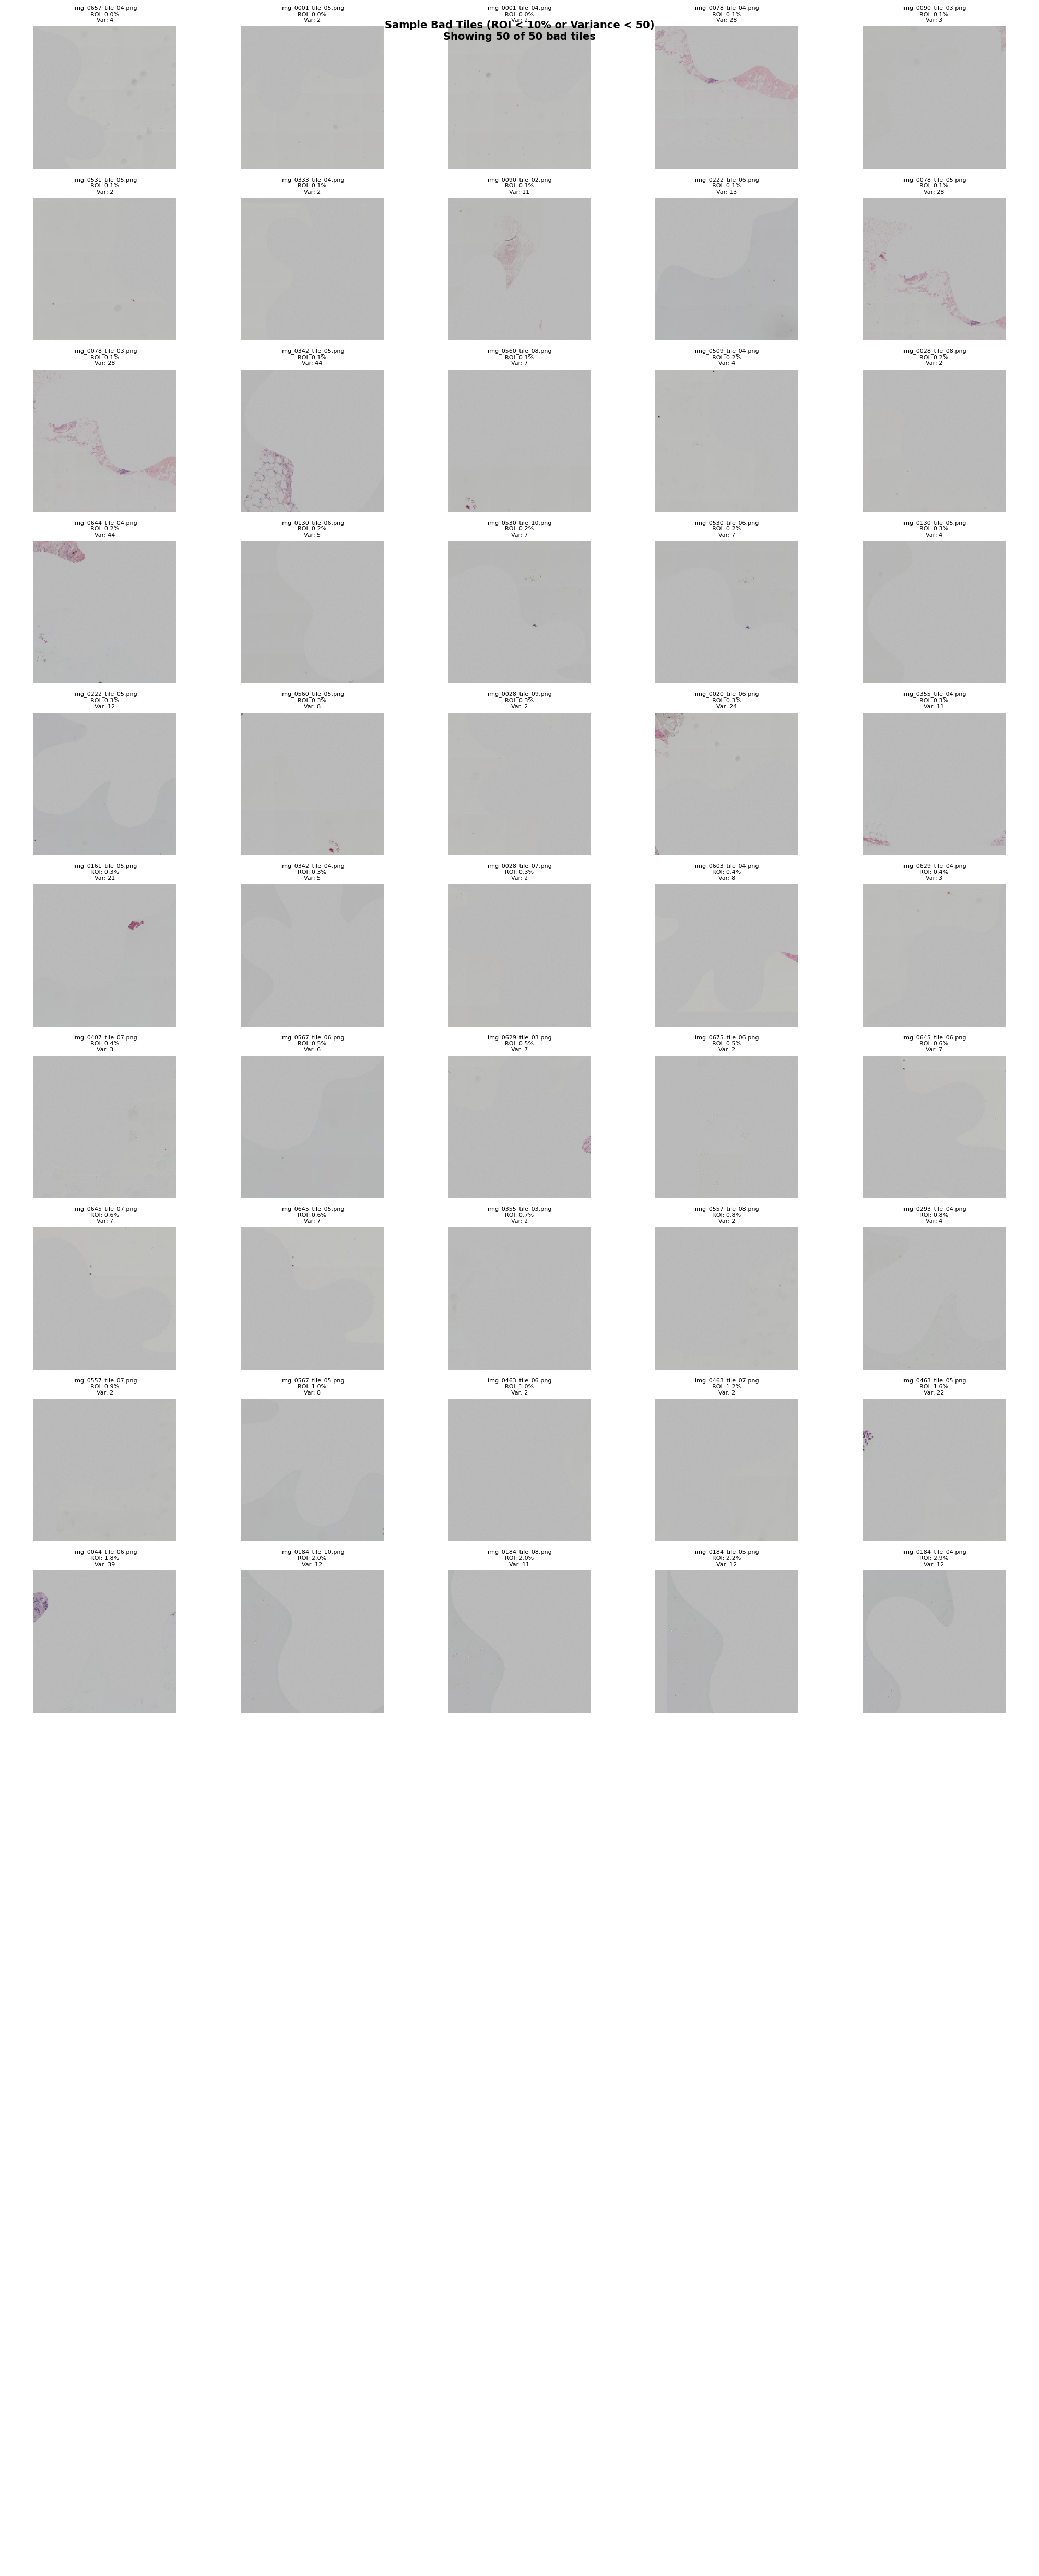

In [ ]:
# Visualize some bad tiles to understand what's being filtered
print("Visualizing sample bad tiles...\n")

bad_tile_samples = [(path, q) for path, q in tile_quality.items() if not q['is_good']]

if bad_tile_samples:
    # Sort by lowest ROI coverage
    bad_tile_samples.sort(key=lambda x: x[1]['roi_coverage'])

    n_show = min(70, len(bad_tile_samples))
    fig, axes = plt.subplots(15, 5, figsize=(20, 50))
    axes = axes.flatten()

    for i, (tile_path, quality) in enumerate(bad_tile_samples[:n_show]):
        tile_img = np.array(Image.open(tile_path))
        axes[i].imshow(tile_img)
        axes[i].set_title(f'{tile_path.name}\n'
                         f'ROI: {quality["roi_coverage"]:.1f}%\n'
                         f'Var: {quality["variance"]:.0f}',
                         fontsize=8)
        axes[i].axis('off')

    for i in range(n_show, len(axes)):
        axes[i].axis('off')

    plt.suptitle(f'Sample Bad Tiles (ROI < {MIN_ROI_COVERAGE}% or Variance < {MIN_VARIANCE})\n'
                f'Showing {n_show} of {len(bad_tile_samples)} bad tiles',
                fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print("No bad tiles found!")

In [ ]:
# Visualize images where all tiles are bad (to decide if we should remove them)
if images_all_bad:
    print(f"\nVisualizing images where ALL tiles were dropped...\n")

    n_show = min(10, len(images_all_bad))
    fig, axes = plt.subplots(2, 5, figsize=(20, 8))
    axes = axes.flatten()

    for i, (img_id, n_tiles) in enumerate(images_all_bad[:n_show]):
        # Load original image
        img_path = root / f'img_{img_id}.png'
        mask_path = root / f'mask_{img_id}.png'

        if img_path.exists():
            img = np.array(Image.open(img_path))
            axes[i].imshow(img)

            # Overlay mask if exists
            if mask_path.exists():
                mask = np.array(Image.open(mask_path))
                if mask.ndim == 3:
                    mask = mask[:, :, 0]
                mask_bool = mask > 0
                axes[i].imshow(np.ma.masked_where(~mask_bool, mask_bool),
                             cmap='Reds', alpha=0.3)

            axes[i].set_title(f'img_{img_id}\n{n_tiles} tiles (all bad)',
                            fontsize=10, color='red')
        else:
            axes[i].text(0.5, 0.5, 'Image not found',
                        ha='center', va='center')
            axes[i].set_title(f'img_{img_id}', fontsize=10)

        axes[i].axis('off')

    # Hide unused subplots
    for i in range(n_show, len(axes)):
        axes[i].axis('off')

    plt.suptitle(f'Images with ALL Tiles Dropped (Quality Too Low)\n'
                f'Total: {len(images_all_bad)} images',
                fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print("\n✓ No images have all tiles dropped - all images have at least one good tile!")



✓ No images have all tiles dropped - all images have at least one good tile!


In [ ]:
# Create filtered tiles directory (only good tiles)
filtered_tiles_dir = Path('bbox_data_cleaned/train_tiles_filtered/')
filtered_tiles_dir.mkdir(exist_ok=True)

print(f"Copying good tiles to {filtered_tiles_dir}...\n")

copied_tiles = 0
skipped_tiles = 0

for tile_path, quality in tile_quality.items():
    if quality['is_good']:
        # Copy tile image
        dest_path = filtered_tiles_dir / tile_path.name
        Image.fromarray(np.array(Image.open(tile_path))).save(dest_path)

        # Copy corresponding mask
        parts = tile_path.stem.split('_')
        img_id = parts[1]
        tile_num = parts[3]
        mask_name = f'mask_{img_id}_tile_{tile_num}.png'
        mask_src = tiles_dir / mask_name
        mask_dst = filtered_tiles_dir / mask_name

        if mask_src.exists():
            Image.fromarray(np.array(Image.open(mask_src))).save(mask_dst)

        copied_tiles += 1
    else:
        skipped_tiles += 1

print(f"{'='*60}")
print(f"Filtering complete!")
print(f"{'='*60}")
print(f"Good tiles copied: {copied_tiles}")
print(f"Bad tiles skipped: {skipped_tiles}")
print(f"Output directory: {filtered_tiles_dir}")
print(f"{'='*60}")

# Report on images with all tiles dropped
if images_all_bad:
    print(f"\n⚠ WARNING: {len(images_all_bad)} images have ALL tiles dropped:")
    print(f"These images might need to be removed from train_labels.csv")
    print(f"\nImage IDs with all tiles dropped:")
    for img_id, n_tiles in images_all_bad:
        print(f"  img_{img_id} ({n_tiles} tiles)")


Copying good tiles to bbox_data_cleaned\train_tiles_filtered...

Filtering complete!
Good tiles copied: 2776
Bad tiles skipped: 50
Output directory: bbox_data_cleaned\train_tiles_filtered


In [ ]:
# Optional: Remove images with all bad tiles from train_labels.csv
# Run this cell only if you want to actually remove these images

import pandas as pd

if images_all_bad:
    labels_path = Path('bbox_data_cleaned/train_labels.csv')

    if labels_path.exists():
        # Load labels
        df = pd.read_csv(labels_path)
        print(f"Original dataset: {len(df)} images")
        print(f"Label distribution:\n{df['label'].value_counts()}\n")

        # Get list of image filenames to remove
        remove_names = [f'img_{img_id}.png' for img_id, _ in images_all_bad]

        # Filter out images with all bad tiles
        df_filtered = df[~df['sample_index'].isin(remove_names)]

        print(f"After removing images with all bad tiles: {len(df_filtered)} images")
        print(f"Removed: {len(df) - len(df_filtered)} images")
        print(f"Label distribution after filtering:\n{df_filtered['label'].value_counts()}\n")

        # Show which labels were affected
        df_removed = df[df['sample_index'].isin(remove_names)]
        if len(df_removed) > 0:
            print(f"Removed images by label:")
            print(df_removed['label'].value_counts())
            print(f"\nRemoved image IDs: {sorted([img_id for img_id, _ in images_all_bad])}")

        # Ask for confirmation before saving (comment out to auto-save)
        print("\n" + "="*60)
        print("TO SAVE: Uncomment the save line below")
        print("="*60)
        df_filtered.to_csv(Path('masked_data/train_labels_filtered.csv'), index=False)
        print(f"✓ Saved filtered labels to masked_data/train_labels_filtered.csv")
    else:
        print(f"Labels file not found: {labels_path}")
else:
    print("No images to remove - all images have at least one good tile!")


No images to remove - all images have at least one good tile!


In [ ]:
# Apply Approach 3 (BBox Crop + 512×512 Padding) to test_data,
# then extract ROI-guided tiles and filter them, mirroring train_data flow.

test_source_dir = Path('bbox_data_cleaned/test_data')
test_tiles_dir = Path('bbox_data_cleaned/test_tiles')
test_tiles_dir.mkdir(exist_ok=True)
test_tiles_filtered_dir = Path('bbox_data_cleaned/test_tiles_filtered')
test_tiles_filtered_dir.mkdir(exist_ok=True)

# 1) BBox crop + padding for all test images (in-place)
print("Applying Approach 3 (BBox Crop + 512×512 Padding) to test_data...\n")
processed_test = 0

for img_path in sorted(test_source_dir.glob('img_*.png')):
    img_id = img_path.stem.split('_')[1]
    mask_path = test_source_dir / f'mask_{img_id}.png'

    if not mask_path.exists():
        print(f"Warning: mask not found for {img_path.name}, skipping...")
        continue

    img = np.array(Image.open(img_path))
    mask = np.array(Image.open(mask_path))
    if mask.ndim == 3:
        mask = mask[:, :, 0]

    img_processed, mask_processed = crop_by_bbox_with_mask(img, mask)

    Image.fromarray(img_processed).save(test_source_dir / f'img_{img_id}.png')
    Image.fromarray(mask_processed).save(test_source_dir / f'mask_{img_id}.png')

    processed_test += 1
    if processed_test % 50 == 0:
        print(f"Processed {processed_test} test images...")

print(f"\nDone. Total test images processed: {processed_test}")

# 2) Extract tiles for test_data using existing ROI-guided tiler
print("\nExtracting tiles for test_data...\n")
old_root, old_tiles_dir = root, tiles_dir
total_test_tiles = 0
try:
    root = test_source_dir
    tiles_dir = test_tiles_dir
    tiles_dir.mkdir(exist_ok=True)

    for img_path in sorted(root.glob('img_*.png')):
        total_test_tiles += process_image(img_path)

finally:
    root = old_root
    tiles_dir = old_tiles_dir

print(f"\nTotal test tiles saved: {total_test_tiles}")

# 3) Filter test tiles using same quality criteria as train
print("\nFiltering test tiles by ROI coverage and variance...\n")
tile_quality_test = {}
good_tiles_test = 0
bad_tiles_test = 0

for tile_path in sorted(test_tiles_dir.glob('img_*_tile_*.png')):
    parts = tile_path.stem.split('_')
    img_id = parts[1]
    tile_num = parts[3]

    mask_path = test_tiles_dir / f'mask_{img_id}_tile_{tile_num}.png'
    if not mask_path.exists():
        print(f"Warning: mask not found for {tile_path.name}, skipping...")
        continue

    tile_img = np.array(Image.open(tile_path))
    tile_mask = np.array(Image.open(mask_path))
    if tile_mask.ndim == 3:
        tile_mask = tile_mask[:, :, 0]

    quality = assess_tile_quality(tile_img, tile_mask)
    tile_quality_test[tile_path] = quality

    if quality['is_good']:
        Image.fromarray(tile_img).save(test_tiles_filtered_dir / tile_path.name)
        Image.fromarray(tile_mask).save(test_tiles_filtered_dir / f'mask_{img_id}_tile_{tile_num}.png')
        good_tiles_test += 1
    else:
        bad_tiles_test += 1

print(f"Filtering complete.")
print(f"  Good test tiles: {good_tiles_test}")
print(f"  Bad test tiles: {bad_tiles_test}")
print(f"  Output directory: {test_tiles_filtered_dir}")

Applying Approach 3 (BBox Crop + 512×512 Padding) to test_data...

Processed 50 test images...
Processed 100 test images...
Processed 150 test images...
Processed 200 test images...
Processed 250 test images...
Processed 300 test images...
Processed 350 test images...
Processed 400 test images...
Processed 450 test images...

Done. Total test images processed: 477

Extracting tiles for test_data...

img_0000.png: saved 3 tiles.
img_0001.png: saved 5 tiles.
img_0002.png: saved 10 tiles.
img_0003.png: saved 6 tiles.
img_0004.png: saved 5 tiles.
img_0005.png: saved 2 tiles.
img_0006.png: saved 10 tiles.
img_0007.png: saved 4 tiles.
img_0008.png: saved 3 tiles.
img_0009.png: saved 7 tiles.
img_0010.png: saved 2 tiles.
img_0011.png: saved 5 tiles.
img_0012.png: saved 6 tiles.
img_0013.png: saved 3 tiles.
img_0014.png: saved 8 tiles.
img_0015.png: saved 4 tiles.
img_0016.png: saved 2 tiles.
img_0017.png: saved 4 tiles.
img_0018.png: saved 2 tiles.
img_0019.png: saved 2 tiles.
img_0020.png: s

In [ ]:
# Convert existing tiles to H&E visualization and save to tiles_he
he_dir = Path('masked_data/tiles_filtered_he_train')
he_dir.mkdir(exist_ok=True)
filtered_tiles_dir = Path('masked_data/train_tiles_filtered/')

def tile_to_he(img):
    # Convert RGB to HED optical density, drop DAB channel, convert back
    hed = rgb2hed(img)
    hed_he = hed.copy()
    hed_he[..., 2] = 0  # zero DAB
    rgb_he = hed2rgb(hed_he)
    rgb_he = np.clip(rgb_he, 0, 1)
    return (rgb_he * 255).astype(np.uint8)


saved_he = 0
for tile_path in sorted(filtered_tiles_dir.glob('img_*_tile_*.png')):
    img = np.array(Image.open(tile_path))
    he_img = tile_to_he(img)
    out_path = he_dir / tile_path.name
    Image.fromarray(he_img).save(out_path)
    saved_he += 1
print(f'Saved {saved_he} H&E tiles to {he_dir}')
